# Trabajo parcial — Procesamiento de Imágenes
## Detección de cambios de escena en un video de Neymar

**Integrantes:**
- Barrientos Villalta, Vanessa Jazmin
- Del Castillo Mendoza, Matias Javier
- Rivera Hernandez, Gabriel Omar
- Del Solar, Joaquin

Este notebook desarrolla todos los puntos del trabajo: selección del video (1), identificación manual de escenas (2) el desarrollo completo en notebook (3.1–3.8: extracción de fotogramas, histogramas de color, distancia coseno, análisis de distancias, umbral, detección automática, fotogramas representativos y GIF resumen), la comparación entre detección manual y automática (4) y las conclusiones (5).

Ejecutar las celdas de arriba hacia abajo. Los archivos se guardan en el directorio de trabajo: la raíz del proyecto al ejecutar Jupyter allí, o `/content` en Google Colab. En Colab deben descargarse los resultados antes de cerrar la sesión.

### Preparación del entorno
Se utiliza `gdown` para descargar desde Google Drive, OpenCV para leer el MP4 y guardar imágenes, y Pillow/Matplotlib para la revisión visual. `%pip` instala en el entorno del kernel; no se importa `google.colab.files`, para que también funcione en Jupyter local.

In [107]:
%pip install -q gdown opencv-python-headless numpy matplotlib pillow

In [108]:
from pathlib import Path
import csv
import json
import math
import re
import cv2
import gdown
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image as PILImage, ImageDraw
from IPython.display import Video, display, Markdown, Image

RAIZ = Path.cwd().resolve()
ID_DRIVE = "13Hk50fmb6Kgv6-BCjES7Dz5r6Yg4Wi3K"
URL_DRIVE = f"https://drive.google.com/file/d/{ID_DRIVE}/view"
RUTA_VIDEO = RAIZ / "neymar.mp4"
CARPETA_FRAMES = RAIZ / "frames_originales"
CARPETA_REVISION = RAIZ / "revision_visual"
print(f"Directorio de trabajo: {RAIZ}")

Directorio de trabajo: /content


## 1. Selección del video

Se conserva el video de **Neymar** seleccionado por el equipo. Es una compilación de calentamiento, jugadas, regates, celebraciones y momentos con trofeos del FC Barcelona.

- **Formato:** MP4; archivo local `neymar.mp4`.
- **Fuente:** enlace de Google Drive proporcionado en el código original; se conserva el archivo descargado, sin recortar ni cambiar su resolución.
- **Duración comprobada:** aproximadamente 3 min 31 s; cumple el intervalo aproximado de 3 a 5 minutos.
- **Calidad:** 640 × 360 píxeles; permite distinguir los jugadores, el terreno y cambios de plano. Es suficiente para este ejercicio, aunque no es alta definición.
- **Cambios visuales:** contiene primeros planos, tomas generales de partidos, repeticiones desde otros ángulos y celebraciones.
- **Originalidad frente al ejemplo de clase:** es un video distinto del utilizado como ejemplo en clase; el equipo lo seleccionó por su variedad de planos (primeros planos, tomas generales, repeticiones y celebraciones).

La siguiente celda fija explícitamente el nombre de descarga: así OpenCV abre el mismo archivo, aunque el nombre original en Drive sea diferente.

In [109]:
# Se reutiliza el MP4 si ya está disponible. Cambiar a True para descargarlo otra vez.
FORZAR_DESCARGA = False
if FORZAR_DESCARGA or not RUTA_VIDEO.is_file() or RUTA_VIDEO.stat().st_size == 0:
    ruta_temporal = RAIZ / "neymar.descarga.mp4"
    resultado = gdown.download(id=ID_DRIVE, output=str(ruta_temporal), quiet=False)
    if resultado is None or not ruta_temporal.is_file() or ruta_temporal.stat().st_size == 0:
        raise RuntimeError("No se pudo descargar el video. Verificar el ID y los permisos de Drive.")
    prueba = cv2.VideoCapture(str(ruta_temporal))
    try:
        legible, _ = prueba.read()
        if not prueba.isOpened() or not legible:
            raise RuntimeError("La descarga no es un video legible. Revisar el archivo de Drive.")
    finally:
        prueba.release()
    ruta_temporal.replace(RUTA_VIDEO)
else:
    print("Se reutiliza el video local; no se vuelve a descargar.")
print(f"Archivo: {RUTA_VIDEO.name} ({RUTA_VIDEO.stat().st_size / 1024**2:.2f} MiB)")
display(Markdown(f"[Abrir el video original en Google Drive]({URL_DRIVE})"))

Se reutiliza el video local; no se vuelve a descargar.
Archivo: neymar.mp4 (17.25 MiB)


[Abrir el video original en Google Drive](https://drive.google.com/file/d/13Hk50fmb6Kgv6-BCjES7Dz5r6Yg4Wi3K/view)

In [110]:
cap = cv2.VideoCapture(str(RUTA_VIDEO))
try:
    if not cap.isOpened():
        raise RuntimeError(f"OpenCV no puede abrir {RUTA_VIDEO.name}.")
    fps = float(cap.get(cv2.CAP_PROP_FPS))
    ancho = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    alto = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames_declarado = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if not math.isfinite(fps) or fps <= 0 or min(ancho, alto, total_frames_declarado) <= 0:
        raise RuntimeError("El video no tiene metadatos válidos para esta lectura.")
    duracion_s = total_frames_declarado / fps
finally:
    cap.release()

def tiempo_texto(segundos):
    """Representación MM:SS.s; conserva décimas en los límites aproximados."""
    decimas = round(float(segundos) * 10)
    minutos, resto = divmod(decimas, 600)
    segundos_enteros, decimal = divmod(resto, 10)
    return f"{minutos:02d}:{segundos_enteros:02d}.{decimal}"

print(f"Duración: {tiempo_texto(duracion_s)} ({duracion_s:.3f} s)")
print(f"¿Duración dentro de 3–5 minutos?: {'Sí' if 180 <= duracion_s <= 300 else 'No; revisar selección'}")

Duración: 03:31.5 (211.467 s)
¿Duración dentro de 3–5 minutos?: Sí


### Reproducción del video
El video completo se reprodujo para identificar cada corte, pausando o reduciendo la velocidad cuando fue necesario. El reproductor local usa el archivo sin incrustar sus 18 MB en el notebook. Si no reproduce en Colab o el navegador no reconoce el códec, usar el enlace de Drive de arriba o abrir `neymar.mp4` en un reproductor local.

In [111]:
display(Video(str(RUTA_VIDEO), embed=False, width=min(ancho, 640)))

## 2. Identificación manual de escenas

**Criterio de segmentación:** se registra un nuevo segmento cuando se observa un corte de edición a otro clip o un cambio de cámara/plano claramente diferenciado, incluidas repeticiones de una misma jugada. No se considera nueva escena cada movimiento de Neymar, del balón o cada desplazamiento/zoom continuo de la cámara. Este criterio debe mantenerse cuando se compare con el método automático.

**Procedencia y precisión:** el equipo identificó los cortes reproduciendo el video completo y luego ubicó cada límite en el fotograma del corte, revisando los fotogramas de alrededor. Por eso los tiempos tienen una precisión de un fotograma (1/30 s ≈ 0,03 s). Resultado: **54 escenas (53 cambios)**.

**Cómo se construyó y corrigió la referencia:** la primera versión de la tabla se armó revisando láminas cada 0,5 s y tenía errores. Al revisar los falsos cambios y las omisiones del método automático aparecieron cuatro límites mal puestos: 00:06.8 y 03:28.2 eran cortes reales que faltaban, y 01:42.0 y 02:08.5 no eran cortes. Es decir, **la referencia se corrigió después de revisar los errores del algoritmo**. Luego el equipo volvió a contar todas las escenas viendo el video completo y ubicó cada límite en su fotograma revisando visualmente los fotogramas de alrededor; como apoyo para no pasar por alto planos breves se usó una diferencia de píxeles en escala de grises, independiente del histograma HSV y del umbral. Ese recuento confirmó las cuatro correcciones y dio la tabla final. Como parte de la referencia se revisó a partir de la salida del método, las métricas de 3.5 deben leerse como optimistas.

**Casos límite según el criterio:** no se cuentan como cambio de escena los movimientos de cámara continuos aunque sean bruscos: Neymar bajando la cabeza (≈ 12–14 s), el alejamiento y giro rápido de la cámara hacia el área (≈ 19–21 s), las tomas con cámara en mano de las celebraciones (≈ 41–47 s y ≈ 188–193 s) ni el destello blanco de un fotograma a 118,3 s, que ocurre dentro de la misma toma.

La lista editable contiene el inicio, en segundos, y la descripción de cada segmento. El final se obtiene del inicio del siguiente segmento; el último termina al finalizar el video. Los intervalos son `[inicio, final)`, sin huecos ni solapamientos. La primera escena empieza en cero y **no** representa un cambio de escena.

In [112]:
# Registro manual de escenas: (inicio en segundos, descripción).
# Revisado por el equipo con el video completo; límites ajustados al fotograma del corte (1/30 s).
# Cada fila corresponde a un plano/clip visual, no a una escena detectada por código.
escenas_anotadas = [
    (0.00,   "Neymar con chaqueta de calentamiento, junto a otro hombre."),
    (6.80,   "Neymar de espaldas, con las luces del estadio al fondo."),
    (8.10,   "Neymar con camiseta del Barcelona entre el público, señalando hacia arriba."),
    (11.37,  "Primer plano: Neymar mira al cielo y baja la cabeza (una sola toma)."),
    (14.53,  "Plano más cerrado: Neymar se lleva las manos a la cabeza."),
    (16.27,  "Conducción por la banda con camiseta naranja; la cámara se aleja y gira hasta el área."),
    (21.87,  "Plano general amplio del estadio durante un ataque."),
    (29.00,  "Plano cercano del regate ante un defensor celeste."),
    (31.63,  "Neymar ante defensores de gris; termina cayendo."),
    (33.87,  "Plano general del ataque."),
    (37.07,  "Plano general desde otro ángulo, con la portería."),
    (41.53,  "Neymar corre a celebrar hacia la tribuna (cámara en mano)."),
    (47.57,  "Selfie con un teléfono junto a sus compañeros."),
    (54.50,  "Neymar levanta un trofeo entre compañeros y fotógrafos."),
    (59.23,  "Plano general de una llegada al área ante un equipo de amarillo."),
    (61.03,  "Repetición a nivel de campo de la misma acción."),
    (63.07,  "Repetición desde detrás de la portería."),
    (64.57,  "Plano general de una nueva jugada."),
    (66.93,  "Plano cercano ante un rival de blanco y negro."),
    (68.80,  "Regate en la banda ante un defensor de blanco y azul."),
    (70.83,  "Detalle de los pies y el balón."),
    (72.10,  "Plano general ante rivales de amarillo."),
    (74.67,  "Plano más cercano de la misma jugada."),
    (76.23,  "Plano general: Neymar de amarillo ante rivales celestes."),
    (77.63,  "Repetición cercana ante los celestes."),
    (79.57,  "Neymar de rojo ante rivales de franjas azules y blancas."),
    (83.40,  "Plano general ante rivales de franjas rojas y blancas."),
    (90.77,  "Otra jugada ante el mismo equipo."),
    (96.03,  "Plano general largo ante rivales de blanco y azul."),
    (104.53, "Ataque y remate desde otro plano general."),
    (109.70, "Plano general breve desde otro ángulo."),
    (110.27, "Plano a ras de campo: regate ante un defensor de blanco."),
    (114.23, "Disputa del balón ante rivales celestes."),
    (116.13, "Controla un balón aéreo junto a la publicidad de MasterCard (incluye un destello blanco a 118,3 s)."),
    (121.03, "Plano general de un regate junto a la banda."),
    (123.73, "Repetición cercana del regate."),
    (125.13, "Plano general de una conducción hasta el área."),
    (129.80, "Plano cercano: eleva el balón y supera a los defensores."),
    (134.57, "Plano general de una conducción larga."),
    (143.17, "Jugada con la publicidad de BBVA al fondo."),
    (147.47, "Plano general de otro regate."),
    (152.80, "Ante rivales de rojo y blanco (publicidad de PlayStation)."),
    (159.60, "Nueva jugada en plano general."),
    (166.07, "Plano general de una conducción ante rivales de blanco."),
    (173.03, "Detalle de los pies y el balón."),
    (174.57, "Plano general ante rivales de amarillo."),
    (179.37, "A ras de campo, ante rivales de blanco y negro."),
    (181.37, "Plano general del ataque y gol."),
    (187.90, "Celebración con compañeros y banca (cámara en mano)."),
    (193.40, "Neymar arrodillado, con una cinta blanca en la cabeza."),
    (197.40, "Posan con la copa de Champions League."),
    (200.93, "Foto grupal con el trofeo y la bandera de Brasil."),
    (206.27, "Abrazo con la bandera de Brasil."),
    (208.17, "Neymar de pie en el campo; saluda."),
]

inicios = [inicio for inicio, _ in escenas_anotadas]
if not inicios or inicios[0] != 0 or any(b <= a for a, b in zip(inicios, inicios[1:])):
    raise ValueError("Los inicios deben partir de cero y estar ordenados sin duplicados.")
if inicios[-1] >= duracion_s:
    raise ValueError("El video no coincide con la anotación: revisar los tiempos y la fuente.")

escenas = []
for i, (inicio, descripcion) in enumerate(escenas_anotadas):
    fin = inicios[i + 1] if i + 1 < len(inicios) else duracion_s
    escenas.append({"escena": i + 1, "inicio_s": inicio, "fin_s": fin,
                    "tiempo_inicial": tiempo_texto(inicio), "tiempo_final": tiempo_texto(fin),
                    "descripcion": descripcion})

assert math.isclose(sum(e["fin_s"] - e["inicio_s"] for e in escenas), duracion_s)
lineas = ["| Escena | Tiempo inicial | Tiempo final | Descripción |", "|---:|:---:|:---:|---|"]
lineas += [f'| {e["escena"]} | {e["tiempo_inicial"]} | {e["tiempo_final"]} | {e["descripcion"]} |' for e in escenas]
display(Markdown("\n".join(lineas)))
print(f"Total del registro manual: {len(escenas)} escenas; {len(escenas) - 1} cambios.")

with (RAIZ / "escenas_manuales.csv").open("w", encoding="utf-8-sig", newline="") as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=list(escenas[0]))
    escritor.writeheader()
    escritor.writerows(escenas)
print("Tabla exportada: escenas_manuales.csv")

| Escena | Tiempo inicial | Tiempo final | Descripción |
|---:|:---:|:---:|---|
| 1 | 00:00.0 | 00:06.8 | Neymar con chaqueta de calentamiento, junto a otro hombre. |
| 2 | 00:06.8 | 00:08.1 | Neymar de espaldas, con las luces del estadio al fondo. |
| 3 | 00:08.1 | 00:11.4 | Neymar con camiseta del Barcelona entre el público, señalando hacia arriba. |
| 4 | 00:11.4 | 00:14.5 | Primer plano: Neymar mira al cielo y baja la cabeza (una sola toma). |
| 5 | 00:14.5 | 00:16.3 | Plano más cerrado: Neymar se lleva las manos a la cabeza. |
| 6 | 00:16.3 | 00:21.9 | Conducción por la banda con camiseta naranja; la cámara se aleja y gira hasta el área. |
| 7 | 00:21.9 | 00:29.0 | Plano general amplio del estadio durante un ataque. |
| 8 | 00:29.0 | 00:31.6 | Plano cercano del regate ante un defensor celeste. |
| 9 | 00:31.6 | 00:33.9 | Neymar ante defensores de gris; termina cayendo. |
| 10 | 00:33.9 | 00:37.1 | Plano general del ataque. |
| 11 | 00:37.1 | 00:41.5 | Plano general desde otro ángulo, con la portería. |
| 12 | 00:41.5 | 00:47.6 | Neymar corre a celebrar hacia la tribuna (cámara en mano). |
| 13 | 00:47.6 | 00:54.5 | Selfie con un teléfono junto a sus compañeros. |
| 14 | 00:54.5 | 00:59.2 | Neymar levanta un trofeo entre compañeros y fotógrafos. |
| 15 | 00:59.2 | 01:01.0 | Plano general de una llegada al área ante un equipo de amarillo. |
| 16 | 01:01.0 | 01:03.1 | Repetición a nivel de campo de la misma acción. |
| 17 | 01:03.1 | 01:04.6 | Repetición desde detrás de la portería. |
| 18 | 01:04.6 | 01:06.9 | Plano general de una nueva jugada. |
| 19 | 01:06.9 | 01:08.8 | Plano cercano ante un rival de blanco y negro. |
| 20 | 01:08.8 | 01:10.8 | Regate en la banda ante un defensor de blanco y azul. |
| 21 | 01:10.8 | 01:12.1 | Detalle de los pies y el balón. |
| 22 | 01:12.1 | 01:14.7 | Plano general ante rivales de amarillo. |
| 23 | 01:14.7 | 01:16.2 | Plano más cercano de la misma jugada. |
| 24 | 01:16.2 | 01:17.6 | Plano general: Neymar de amarillo ante rivales celestes. |
| 25 | 01:17.6 | 01:19.6 | Repetición cercana ante los celestes. |
| 26 | 01:19.6 | 01:23.4 | Neymar de rojo ante rivales de franjas azules y blancas. |
| 27 | 01:23.4 | 01:30.8 | Plano general ante rivales de franjas rojas y blancas. |
| 28 | 01:30.8 | 01:36.0 | Otra jugada ante el mismo equipo. |
| 29 | 01:36.0 | 01:44.5 | Plano general largo ante rivales de blanco y azul. |
| 30 | 01:44.5 | 01:49.7 | Ataque y remate desde otro plano general. |
| 31 | 01:49.7 | 01:50.3 | Plano general breve desde otro ángulo. |
| 32 | 01:50.3 | 01:54.2 | Plano a ras de campo: regate ante un defensor de blanco. |
| 33 | 01:54.2 | 01:56.1 | Disputa del balón ante rivales celestes. |
| 34 | 01:56.1 | 02:01.0 | Controla un balón aéreo junto a la publicidad de MasterCard (incluye un destello blanco a 118,3 s). |
| 35 | 02:01.0 | 02:03.7 | Plano general de un regate junto a la banda. |
| 36 | 02:03.7 | 02:05.1 | Repetición cercana del regate. |
| 37 | 02:05.1 | 02:09.8 | Plano general de una conducción hasta el área. |
| 38 | 02:09.8 | 02:14.6 | Plano cercano: eleva el balón y supera a los defensores. |
| 39 | 02:14.6 | 02:23.2 | Plano general de una conducción larga. |
| 40 | 02:23.2 | 02:27.5 | Jugada con la publicidad de BBVA al fondo. |
| 41 | 02:27.5 | 02:32.8 | Plano general de otro regate. |
| 42 | 02:32.8 | 02:39.6 | Ante rivales de rojo y blanco (publicidad de PlayStation). |
| 43 | 02:39.6 | 02:46.1 | Nueva jugada en plano general. |
| 44 | 02:46.1 | 02:53.0 | Plano general de una conducción ante rivales de blanco. |
| 45 | 02:53.0 | 02:54.6 | Detalle de los pies y el balón. |
| 46 | 02:54.6 | 02:59.4 | Plano general ante rivales de amarillo. |
| 47 | 02:59.4 | 03:01.4 | A ras de campo, ante rivales de blanco y negro. |
| 48 | 03:01.4 | 03:07.9 | Plano general del ataque y gol. |
| 49 | 03:07.9 | 03:13.4 | Celebración con compañeros y banca (cámara en mano). |
| 50 | 03:13.4 | 03:17.4 | Neymar arrodillado, con una cinta blanca en la cabeza. |
| 51 | 03:17.4 | 03:20.9 | Posan con la copa de Champions League. |
| 52 | 03:20.9 | 03:26.3 | Foto grupal con el trofeo y la bandera de Brasil. |
| 53 | 03:26.3 | 03:28.2 | Abrazo con la bandera de Brasil. |
| 54 | 03:28.2 | 03:31.5 | Neymar de pie en el campo; saluda. |

Total del registro manual: 54 escenas; 53 cambios.
Tabla exportada: escenas_manuales.csv


### Evidencia y apoyo a la revisión visual
Las siguientes láminas recorren todo el video a intervalos de 0,5 s y muestran el tiempo en segundos. Sirven como apoyo visual para ubicar los cambios y documentar la revisión; los límites exactos se tomaron del video y de los fotogramas de alrededor de cada corte. El muestreo se usa solo para visualizar: en 3.1 se almacenan **todos** los fotogramas, sin saltos.

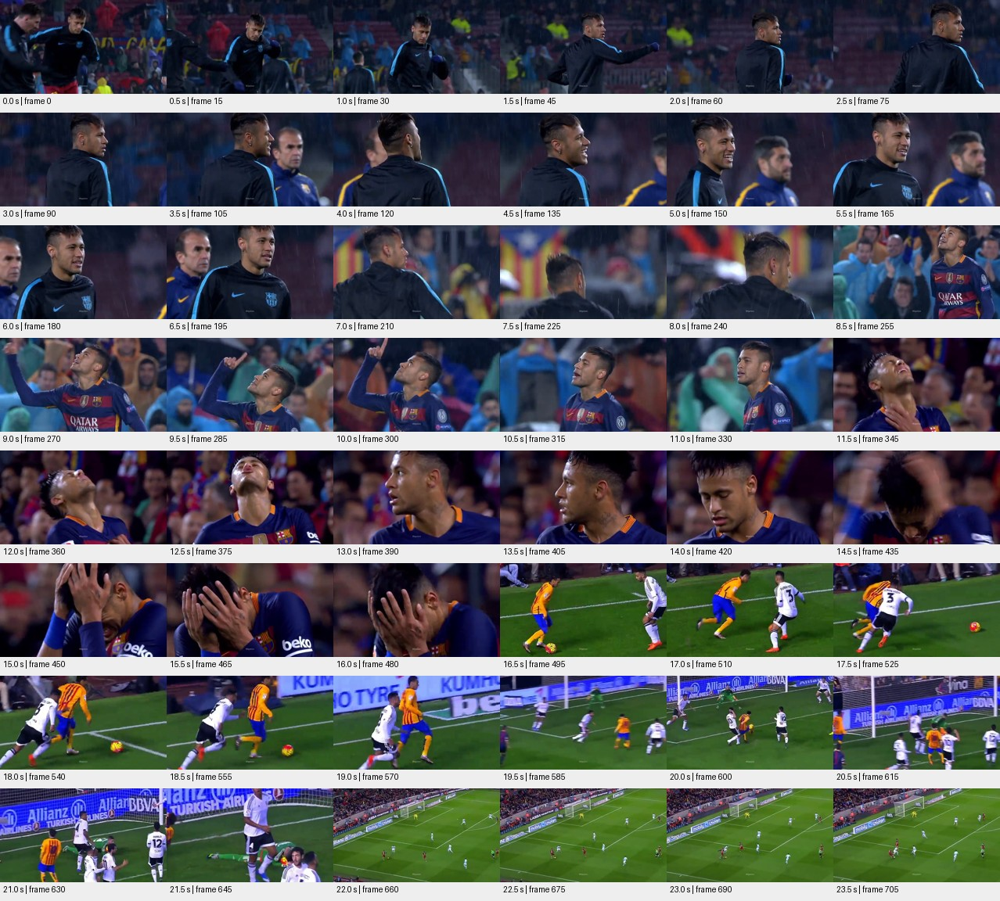

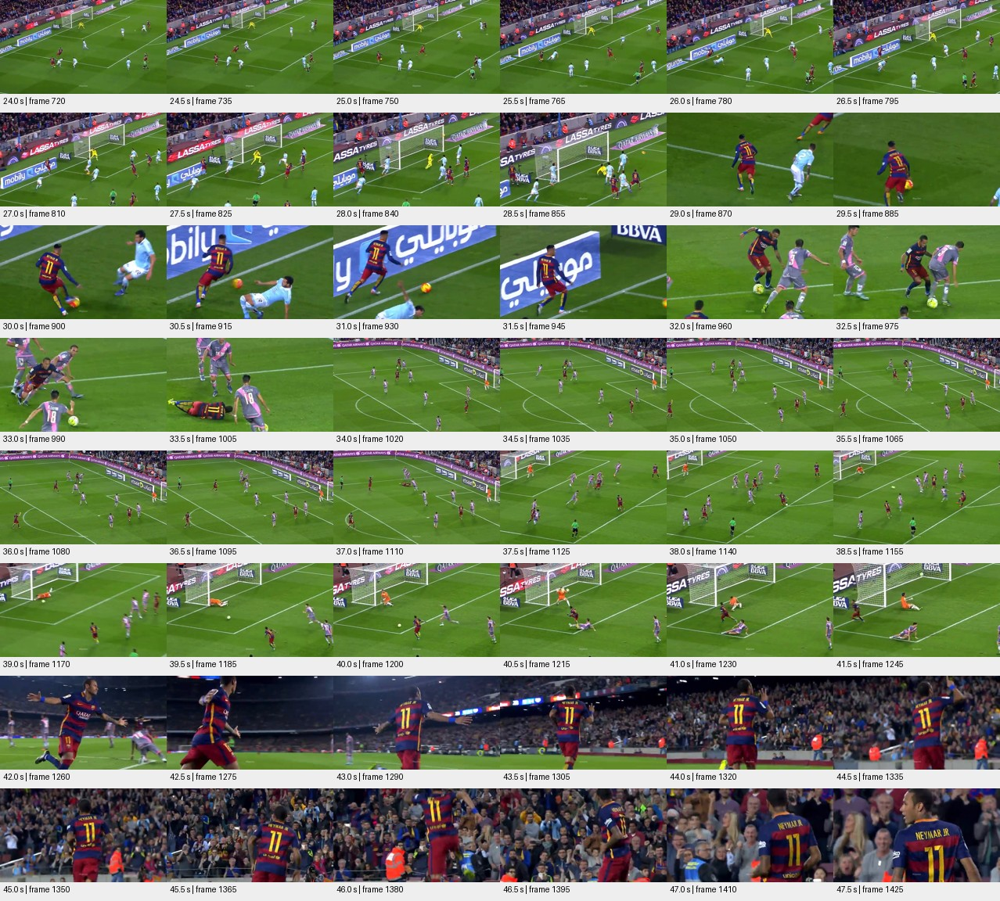

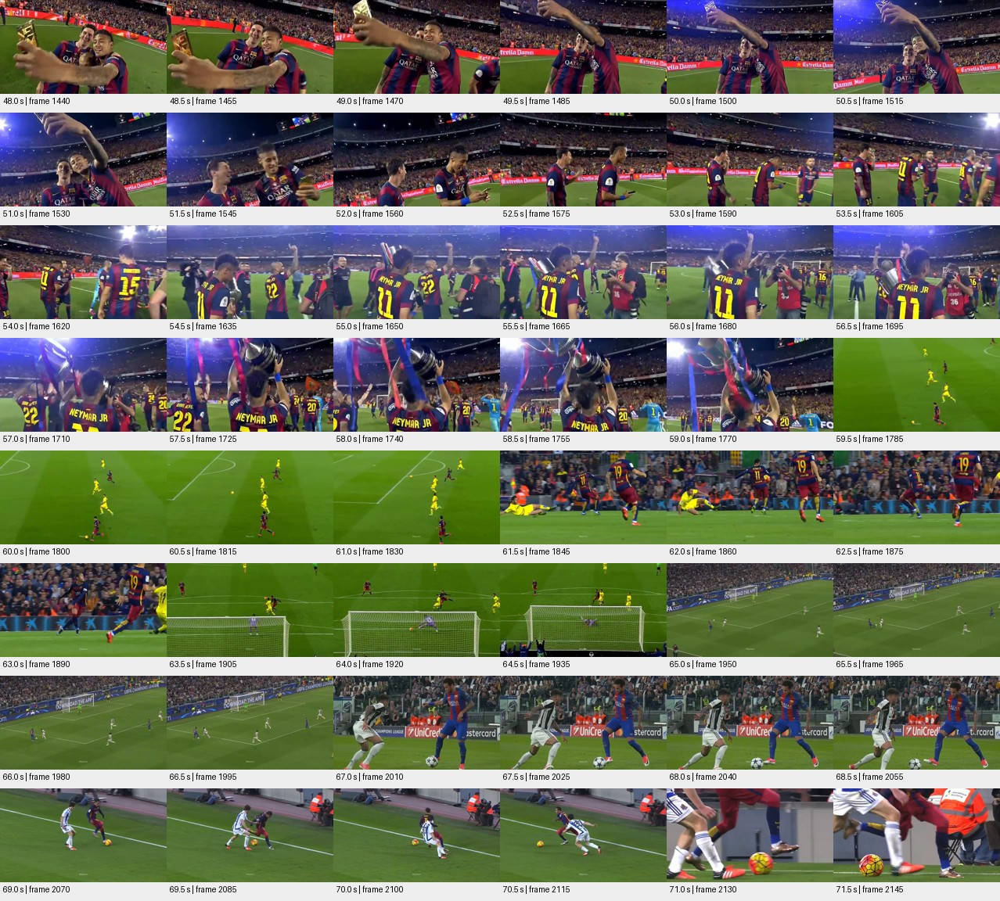

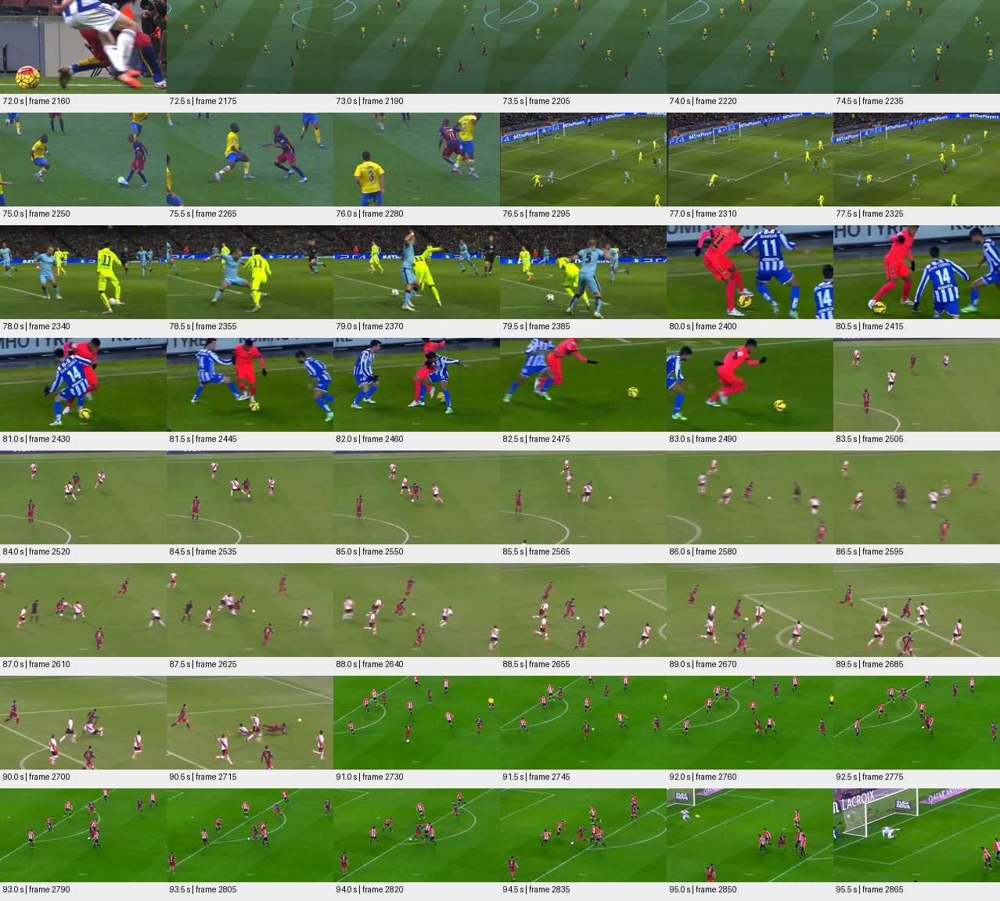

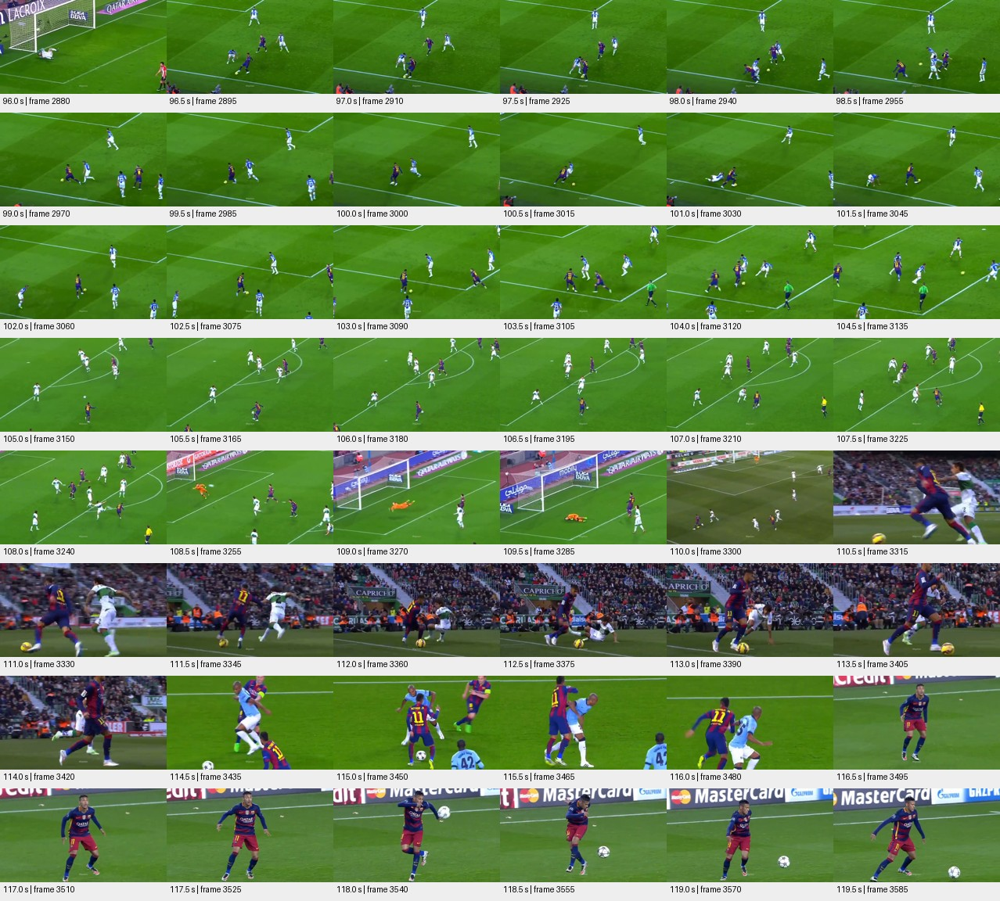

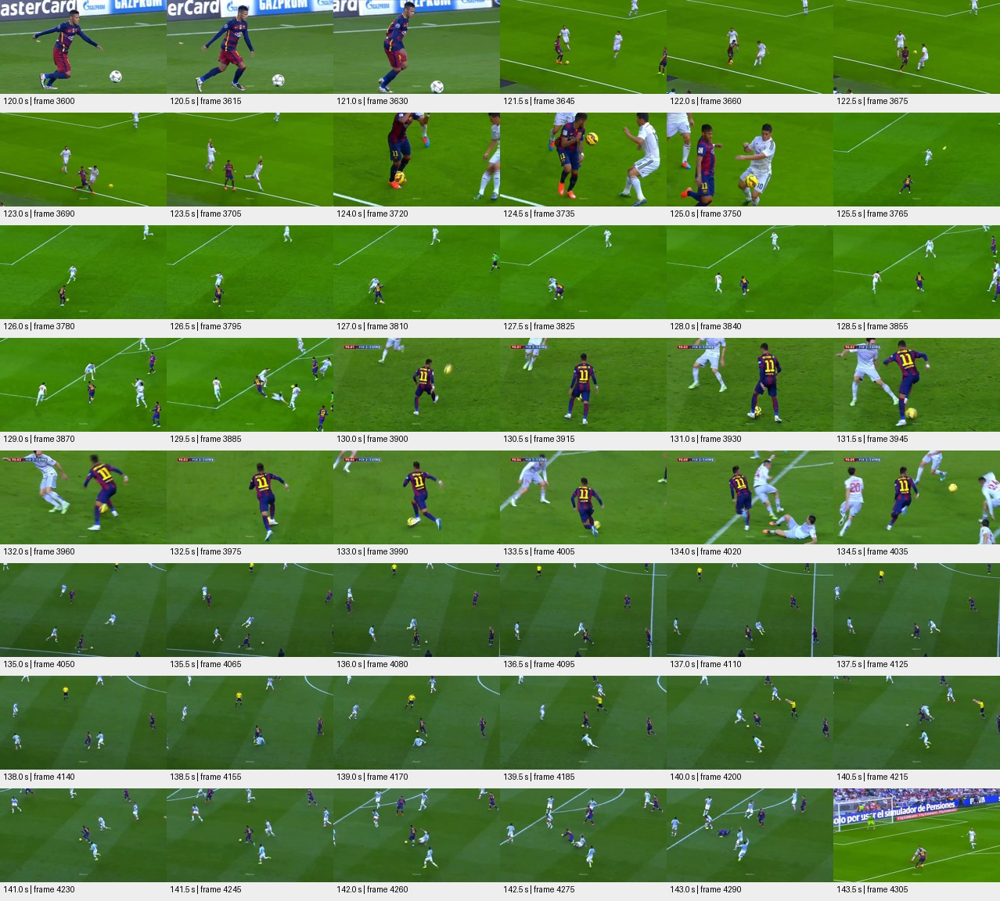

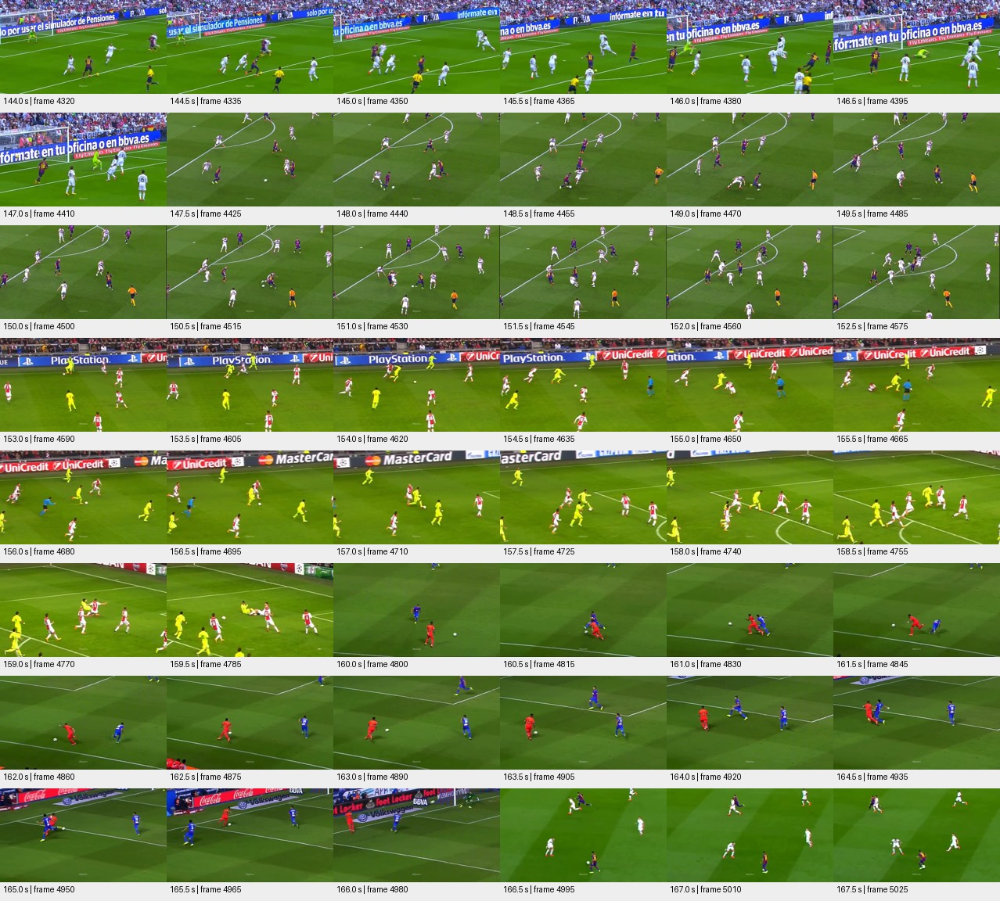

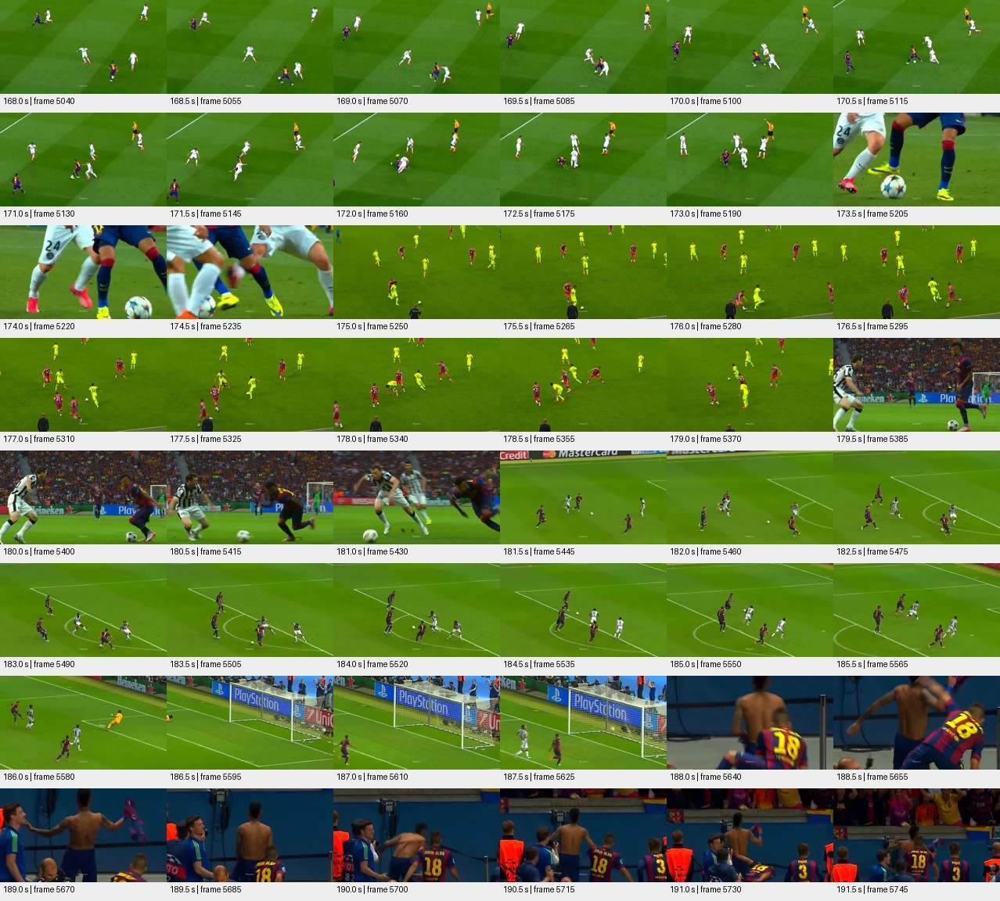

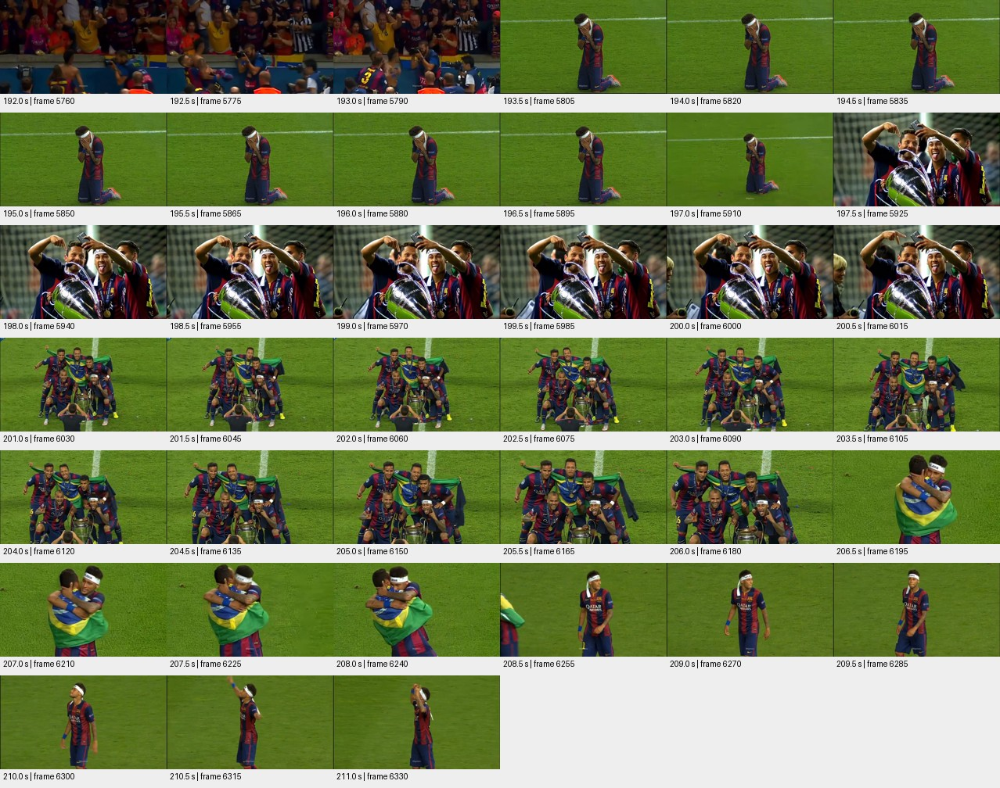

In [113]:
CARPETA_REVISION.mkdir(exist_ok=True)
INTERVALO_REVISION_S = 0.5
MINIATURAS_POR_LAMINA = 48
COLUMNAS = 6
ANCHO_MINIATURA, ALTO_MINIATURA = 213, 120
ALTO_CELDA = 144
indices_revision = list(range(0, total_frames_declarado, round(fps * INTERVALO_REVISION_S)))
cap = cv2.VideoCapture(str(RUTA_VIDEO))
try:
    if not cap.isOpened():
        raise RuntimeError("No se pudo abrir el video para la revisión visual.")
    for inicio in range(0, len(indices_revision), MINIATURAS_POR_LAMINA):
        grupo = indices_revision[inicio:inicio + MINIATURAS_POR_LAMINA]
        filas = math.ceil(len(grupo) / COLUMNAS)
        lamina = PILImage.new("RGB", (COLUMNAS * ANCHO_MINIATURA, filas * ALTO_CELDA), "#eeeeee")
        dibujo = ImageDraw.Draw(lamina)
        for j, indice in enumerate(grupo):
            cap.set(cv2.CAP_PROP_POS_FRAMES, indice)
            ok, frame = cap.read()
            if not ok:
                raise RuntimeError(f"No se pudo revisar el fotograma {indice}.")
            miniatura = PILImage.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            miniatura = miniatura.resize((ANCHO_MINIATURA, ALTO_MINIATURA))
            x, y = (j % COLUMNAS) * ANCHO_MINIATURA, (j // COLUMNAS) * ALTO_CELDA
            lamina.paste(miniatura, (x, y))
            dibujo.text((x + 4, y + ALTO_MINIATURA + 3), f"{indice / fps:.1f} s | frame {indice}", fill="black")
        ruta = CARPETA_REVISION / f"lamina_{inicio // MINIATURAS_POR_LAMINA + 1:02d}.jpg"
        lamina.save(ruta, quality=90)
        display(Image(filename=str(ruta)))
finally:
    cap.release()

## 3. Desarrollo en notebook
### 3.1. Lectura del video y extracción de fotogramas

OpenCV abre el MP4 con `VideoCapture`. `read()` decodifica sucesivamente cada fotograma y `imwrite()` lo guarda en `frames_originales`, conservando su tamaño y sus tres canales de color. No se redimensiona, convierte a grises ni realiza preprocesamiento para características.

Se utiliza **JPEG con calidad 95**, manteniendo el formato del código de referencia y reduciendo el espacio en disco. JPEG tiene compresión con pérdida: los fotogramas no son copias sin pérdida de los píxeles decodificados; esta decisión debe mantenerse en el análisis posterior. La extracción puede tardar y necesita cientos de MB libres.

- Nombres: `frame_00000.jpg`, `frame_00001.jpg`, etc. La numeración empieza en **0** y coincide con el índice de OpenCV.
- Tiempo aproximado: `indice / fps`, adecuado para este video con tasa de 30 FPS. No representa timestamps exactos para un video con tasa variable.
- Cantidad declarada: metadatos del MP4. Cantidad extraída: contador de lecturas y escrituras exitosas; se contrasta con los metadatos y se avisa si difieren, sin inventar imágenes faltantes.
- Duración aproximada: `cantidad / fps`. El tiempo del último fotograma es `(cantidad - 1) / fps`, no el final del video.

Se libera la captura con `finally` incluso si ocurre un error y se verifica el resultado de cada escritura. Al repetir la extracción se sobrescriben los archivos propios; únicamente se eliminan sobrantes con el patrón exacto `frame_XXXXX.jpg`, sin borrar la carpeta completa ni archivos ajenos.

In [114]:
CARPETA_FRAMES.mkdir(exist_ok=True)
RUTA_INDICE = RAIZ / "indice_fotogramas.csv"
indice_temporal = RAIZ / "indice_fotogramas.tmp.csv"
cap = cv2.VideoCapture(str(RUTA_VIDEO))
contador = 0
try:
    if not cap.isOpened():
        raise RuntimeError("No se pudo abrir el video para extraer sus fotogramas.")
    with indice_temporal.open("w", encoding="utf-8", newline="") as archivo:
        escritor = csv.writer(archivo)
        escritor.writerow(["fotograma", "tiempo_s", "ruta"])
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            if frame.shape != (alto, ancho, 3):
                raise RuntimeError(f"Dimensiones inesperadas en el fotograma {contador}: {frame.shape}")
            ruta = CARPETA_FRAMES / f"frame_{contador:05d}.jpg"
            guardado = cv2.imwrite(str(ruta), frame, [cv2.IMWRITE_JPEG_QUALITY, 95])
            if not guardado:
                raise OSError(f"No se pudo guardar {ruta}. Revisar espacio y permisos.")
            escritor.writerow([contador, f"{contador / fps:.6f}", ruta.relative_to(RAIZ).as_posix()])
            contador += 1
            if contador % 1000 == 0:
                print(f"Guardados {contador}/{total_frames_declarado} fotogramas...")
finally:
    cap.release()

if contador == 0:
    raise RuntimeError("No se extrajo ningún fotograma.")
diferencia_frames = total_frames_declarado - contador
if diferencia_frames != 0:
    print(f"ADVERTENCIA: el MP4 declara {total_frames_declarado} fotogramas, pero OpenCV decodificó {contador}.")
    print("read() terminó: puede existir una diferencia de metadatos o un problema de decodificación.")
    print("Se guardan todos los fotogramas legibles; no se rellenan ni se duplican los faltantes.")
    # En este archivo se observan dos fotogramas de diferencia, menos de 0,1 s.
    # Una diferencia grande exige revisar la fuente antes de seguir.
    if abs(diferencia_frames) > max(2, round(fps * 0.1)):
        raise RuntimeError("Diferencia superior a 0,1 s: revisar el video o el decodificador.")

# Limpiar únicamente sobrantes propios después de recorrer todo lo decodificable.
for ruta in CARPETA_FRAMES.iterdir():
    coincidencia = re.fullmatch(r"frame_(\d{5,})\.jpg", ruta.name)
    if ruta.is_file() and coincidencia and int(coincidencia.group(1)) >= contador:
        ruta.unlink()
indice_temporal.replace(RUTA_INDICE)

archivos_frames = [p for p in CARPETA_FRAMES.iterdir() if p.is_file() and re.fullmatch(r"frame_\d{5,}\.jpg", p.name)]
if len(archivos_frames) != contador:
    raise RuntimeError("El número de imágenes guardadas no coincide con el contador.")

metadatos = {
    "video": RUTA_VIDEO.name, "drive_id": ID_DRIVE,
    "fps": fps, "ancho": ancho, "alto": alto,
    "fotogramas_declarados": total_frames_declarado, "fotogramas_extraidos": contador,
    "diferencia_fotogramas": diferencia_frames,
    "duracion_segun_metadatos_s": duracion_s,
    "duracion_aproximada_s": contador / fps,
    "carpeta_fotogramas": CARPETA_FRAMES.name,
    "formato_fotogramas": "JPEG", "calidad_jpeg": 95, "indice_inicial": 0,
    "escenas_registro_manual": len(escenas),
    "intervalo_revision_visual_s": INTERVALO_REVISION_S,
}
(RAIZ / "metadatos_video.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")

resumen = f"""| Característica | Resultado |
|---|---:|
| Cantidad total de fotogramas (MP4) | {total_frames_declarado} |
| Fotogramas extraídos y guardados | {contador} |
| Diferencia (declarados − extraídos) | {diferencia_frames} |
| FPS | {fps:.2f} |
| Resolución (ancho × alto) | {ancho} × {alto} píxeles |
| Duración aproximada | {tiempo_texto(contador / fps)} ({contador / fps:.3f} s) |
| Índice del último fotograma | {contador - 1} |
| Espacio de los JPEG | {sum(p.stat().st_size for p in archivos_frames) / 1024**2:.1f} MiB |
"""
display(Markdown(resumen))
print(f"Carpeta: {CARPETA_FRAMES}")
print("Archivos auxiliares: indice_fotogramas.csv y metadatos_video.json")

Guardados 1000/6344 fotogramas...
Guardados 2000/6344 fotogramas...
Guardados 3000/6344 fotogramas...
Guardados 4000/6344 fotogramas...
Guardados 5000/6344 fotogramas...
Guardados 6000/6344 fotogramas...
ADVERTENCIA: el MP4 declara 6344 fotogramas, pero OpenCV decodificó 6342.
read() terminó: puede existir una diferencia de metadatos o un problema de decodificación.
Se guardan todos los fotogramas legibles; no se rellenan ni se duplican los faltantes.


| Característica | Resultado |
|---|---:|
| Cantidad total de fotogramas (MP4) | 6344 |
| Fotogramas extraídos y guardados | 6342 |
| Diferencia (declarados − extraídos) | 2 |
| FPS | 30.00 |
| Resolución (ancho × alto) | 640 × 360 píxeles |
| Duración aproximada | 03:31.4 (211.400 s) |
| Índice del último fotograma | 6341 |
| Espacio de los JPEG | 323.8 MiB |


Carpeta: /content/frames_originales
Archivos auxiliares: indice_fotogramas.csv y metadatos_video.json


### Comprobación visual de la extracción
Se reabren los JPEG del inicio, mitad y final para comprobar su lectura, color y dimensiones. OpenCV trabaja en BGR; para mostrarlos correctamente en Matplotlib se convierten a RGB. Esta es una comprobación de almacenamiento, **no** la selección automática de fotogramas representativos del punto 3.7.

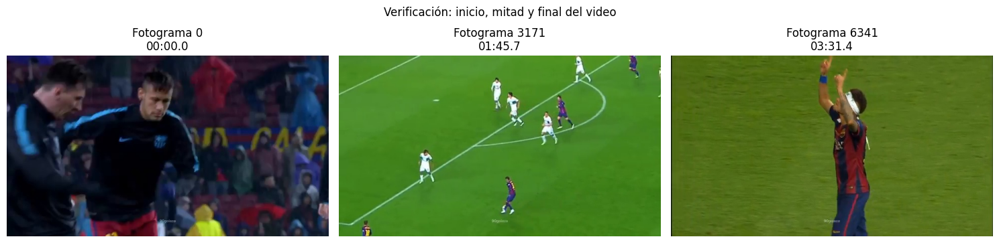

In [115]:
indices_muestra = [0, contador // 2, contador - 1]
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, indice in zip(ejes, indices_muestra):
    ruta = CARPETA_FRAMES / f"frame_{indice:05d}.jpg"
    imagen = cv2.imread(str(ruta))
    if imagen is None or imagen.shape != (alto, ancho, 3):
        raise RuntimeError(f"El JPEG {ruta.name} no se puede leer o tiene dimensiones incorrectas.")
    eje.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    eje.set_title(f"Fotograma {indice}\n{tiempo_texto(indice / fps)}")
    eje.axis("off")
fig.suptitle("Verificación: inicio, mitad y final del video")
plt.tight_layout()
plt.show()

### Resultado y modificaciones frente al código de referencia

Se conservan el ID de Drive, OpenCV y la estructura de nombres de los JPEG. El video se guarda como `neymar.mp4`, el mismo nombre del archivo entregado en el repositorio, para que se reutilice sin volver a descargarlo. Se agregan:

1. Descarga con nombre de salida explícito, validación del MP4 y reutilización del archivo local.
2. Celdas Markdown organizadas según los puntos del enunciado y un registro manual de escenas editable, con criterio de segmentación y tiempos precisos al fotograma.
3. Duración aproximada, validación de FPS y contraste entre fotogramas declarados y realmente guardados.
4. Manejo seguro de recursos, comprobación de cada escritura y limpieza limitada a sobrantes propios.
5. CSV de escenas, índice de fotogramas, metadatos JSON y comprobación visual de las imágenes guardadas.

**Observación real de la extracción:** el MP4 declara 6344 fotogramas, mientras OpenCV decodifica y guarda 6342 (211,400 s frente a 211,467 s según los metadatos). La diferencia de dos fotogramas equivale a aproximadamente 0,067 s. Se informa explícitamente: no se fabrican imágenes para alcanzar el contador declarado y se usan los 6342 JPEG legibles para los puntos posteriores. Sin una inspección adicional del contenedor/decodificador no se atribuye una causa definitiva a la diferencia.

Los fotogramas guardados aquí son la entrada de los puntos 3.2–3.8; el preprocesamiento (reducción de tamaño, suavizado y conversión a HSV) se aplica en memoria en 3.2, sin modificar los JPEG originales.

## 3.2. Extracción de características

Se usa un **histograma de color en el espacio HSV** para cada fotograma guardado en 3.1.

**Preprocesamiento (en memoria, sin alterar los JPEG originales):**
1. **Reducción a 160 × 90 px** (misma relación 16:9). El histograma solo cuenta proporciones de color, así que no necesita la resolución completa; reducir el tamaño acelera el cálculo y promedia ruido de píxeles aislados.
2. **Suavizado gaussiano 3 × 3**, que atenúa el ruido y los artefactos de compresión del MP4/JPEG. Sin él, dos fotogramas casi idénticos podrían caer en bins distintos por variaciones mínimas.
3. **Conversión de BGR a HSV**, que separa el color (matiz H y saturación S) del brillo (V). Así, un cambio de iluminación dentro de la misma toma afecta menos que en RGB, donde los tres canales cambian a la vez.

**Vector de características:** histograma conjunto de los tres canales con 16 × 4 × 4 = **256 bins**. Se dan más bins al matiz (16) porque es el canal que mejor distingue uniformes, césped, tribuna o trofeos; S y V se agrupan en 4 niveles para no ser demasiado sensibles a sombras y brillos. Se normaliza dividiendo por el total de píxeles (**normalización L1**), de modo que cada valor es la **proporción de píxeles** de ese color en la imagen.

**Qué representa y por qué sirve para comparar:** el vector resume *qué colores aparecen y en qué cantidad*, sin importar dónde están. Dos fotogramas de la misma toma tienen casi la misma paleta (aunque Neymar o el balón se muevan), por lo que sus vectores son muy parecidos; en un corte a otro plano, la distribución de colores cambia de golpe. Comparar vectores de 256 números es además mucho más rápido que comparar imágenes de 640 × 360 × 3 píxeles.

> Nota: la normalización no afecta la distancia coseno de 3.3, que ya es invariante a la escala (multiplicar un vector por una constante no cambia su ángulo). Se hace para que el vector tenga interpretación como distribución de probabilidad. Por la misma razón, una normalización MINMAX tampoco aportaría nada con esta distancia.

In [116]:
# 3.2 Extracción de características: histograma de color HSV por fotograma
TAMANO_PROCESADO = (160, 90)   # misma relación 16:9 que el video (640 × 360)
BINS_HSV = [16, 4, 4]          # matiz (H), saturación (S), brillo (V) -> 16·4·4 = 256 valores

def vector_caracteristicas(imagen_bgr):
    # 1) Reducción de tamaño: menos ruido y cómputo; el histograma no depende de la resolución.
    pequena = cv2.resize(imagen_bgr, TAMANO_PROCESADO, interpolation=cv2.INTER_AREA)
    # 2) Suavizado gaussiano: atenúa ruido y artefactos de compresión del MP4/JPEG.
    suavizada = cv2.GaussianBlur(pequena, (3, 3), 0)
    # 3) Conversión a HSV: separa el color (H, S) de la iluminación (V).
    hsv = cv2.cvtColor(suavizada, cv2.COLOR_BGR2HSV)
    # 4) Histograma conjunto de los tres canales, aplanado a un vector de 256 valores.
    hist = cv2.calcHist([hsv], [0, 1, 2], None, BINS_HSV, [0, 180, 0, 256, 0, 256]).flatten()
    # 5) Normalización L1: cada valor es la proporción de píxeles en ese bin (suma 1).
    #    No cambia la distancia coseno (que ya es invariante a escala), pero hace el vector
    #    interpretable como distribución y comparable entre fotogramas.
    return (hist / (hist.sum() + 1e-12)).astype(np.float32)

print("Extrayendo histogramas HSV de los fotogramas guardados en 3.1...")
caracteristicas = np.empty((contador, int(np.prod(BINS_HSV))), dtype=np.float32)
for indice in range(contador):
    imagen = cv2.imread(str(CARPETA_FRAMES / f"frame_{indice:05d}.jpg"))
    if imagen is None:
        raise RuntimeError(f"No se pudo leer frame_{indice:05d}.jpg")
    caracteristicas[indice] = vector_caracteristicas(imagen)

print(f"Matriz de características: {caracteristicas.shape} (fotogramas × bins)")
print(f"Suma de cada vector (debe ser 1): mín {caracteristicas.sum(1).min():.4f}, máx {caracteristicas.sum(1).max():.4f}")

Extrayendo histogramas HSV de los fotogramas guardados en 3.1...
Matriz de características: (6342, 256) (fotogramas × bins)
Suma de cada vector (debe ser 1): mín 1.0000, máx 1.0000


## 3.3. Comparación entre fotogramas consecutivos

Para cada par consecutivo (fotograma 1 con 2, 2 con 3, …, hasta el final) se calcula la **distancia coseno**:

$$d(A,B) = 1 - \frac{A \cdot B}{\lVert A\rVert\,\lVert B\rVert}$$

La fracción es el coseno del ángulo entre los dos vectores. Como los histogramas no tienen valores negativos, el coseno está entre 0 y 1, y la distancia también. Con 6342 fotogramas se obtienen 6341 distancias; `distancias[i]` compara el fotograma `i` con el `i + 1`.

- **Distancia cercana a 0:** los dos histogramas apuntan casi en la misma dirección, es decir, los fotogramas tienen la misma distribución de colores. Es lo normal dentro de una misma toma, donde entre dos fotogramas solo pasan 1/30 s.
- **Distancia relativamente alta:** las proporciones de color son distintas; por ejemplo, se pasa de un plano dominado por el verde del césped a uno con tribuna, piel o una bandera. Un valor cercano a 1 indica que los fotogramas casi no comparten colores.
- **Por qué indica un cambio de escena:** dentro de una toma el contenido cambia de forma gradual, así que la distancia se mantiene baja de un fotograma al siguiente. En un corte de edición la imagen cambia por completo de un fotograma al otro, lo que produce un **pico aislado** en la serie de distancias. Detectar esos picos equivale a detectar cortes.

**Caso de vector nulo:** si uno de los dos histogramas tuviera norma 0, el coseno no está definido. En ese caso se asigna `d = 1` (cambio máximo) para no ocultar un posible corte; solo si ambos son nulos se asigna `d = 0`. Con la normalización L1 de 3.2 esto no ocurre en la práctica (incluso un fotograma negro tiene todos sus píxeles en un bin), pero el código queda protegido.

In [117]:
# 3.3 Distancia coseno entre fotogramas consecutivos: d = 1 - (A·B) / (||A|| ||B||)
distancias = []
print("Calculando distancias coseno...")

for i in range(len(caracteristicas) - 1):
    f_i = caracteristicas[i]
    f_next = caracteristicas[i + 1]

    # Numerador: producto punto
    dot_product = np.dot(f_i, f_next)

    # Denominador: multiplicación de las magnitudes (normas)
    norm_i = np.linalg.norm(f_i)
    norm_next = np.linalg.norm(f_next)

    if norm_i == 0 and norm_next == 0:
        d = 0.0   # ambos vacíos: no hay diferencia observable
    elif norm_i == 0 or norm_next == 0:
        d = 1.0   # solo uno vacío: se trata como cambio máximo, no se oculta
    else:
        d = 1.0 - (dot_product / (norm_i * norm_next))

    distancias.append(max(0.0, float(d)))   # evita valores como -1e-8 por redondeo

distancias = np.array(distancias)   # arreglo NumPy: lo requieren 3.4–3.6
assert len(distancias) == contador - 1
print(f"{len(distancias)} distancias | mín {distancias.min():.4f} | mediana {np.median(distancias):.4f} "
      f"| percentil 99 {np.percentile(distancias, 99):.4f} | máx {distancias.max():.4f}")

Calculando distancias coseno...
6341 distancias | mín 0.0000 | mediana 0.0001 | percentil 99 0.0333 | máx 0.9985


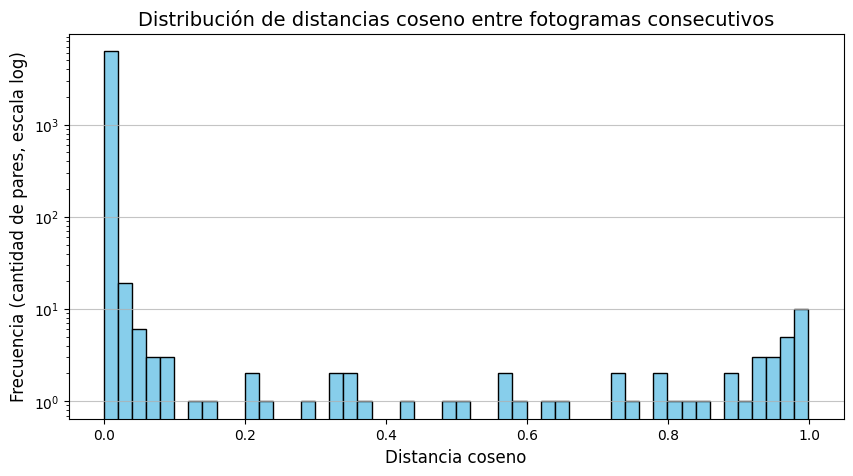

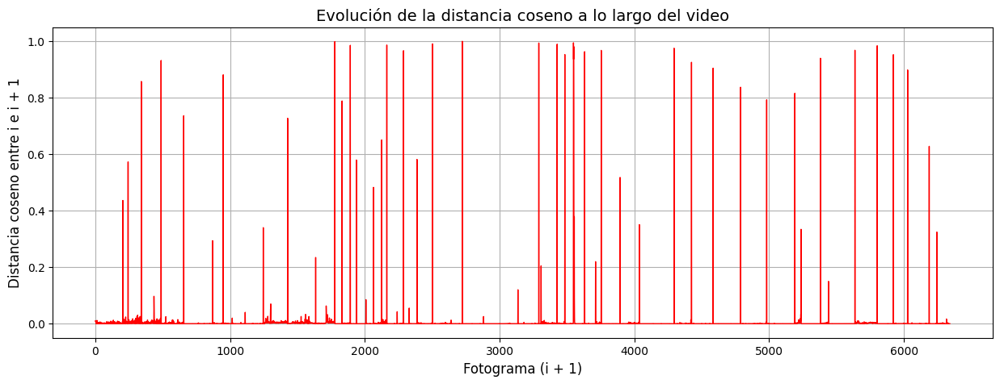

In [118]:
# 3.4 ANÁLISIS DE LAS DISTANCIAS

# a. Histograma de distancias (eje Y logarítmico: la mayoría de pares tiene distancia ~0
#    y, en escala lineal, los valores altos —los cortes— serían invisibles)
plt.figure(figsize=(10, 5))
plt.hist(distancias, bins=50, color='skyblue', edgecolor='black')
plt.yscale('log')
plt.title('Distribución de distancias coseno entre fotogramas consecutivos', fontsize=14)
plt.xlabel('Distancia coseno', fontsize=12)
plt.ylabel('Frecuencia (cantidad de pares, escala log)', fontsize=12)
plt.grid(axis='y', alpha=0.75)
plt.show()

# b. Gráfico de distancia por fotograma
plt.figure(figsize=(15, 5))
plt.plot(np.arange(1, contador), distancias, color='red', linewidth=1)
plt.title('Evolución de la distancia coseno a lo largo del video', fontsize=14)
plt.xlabel('Fotograma (i + 1)', fontsize=12)
plt.ylabel('Distancia coseno entre i e i + 1', fontsize=12)
plt.grid(True)
plt.show()

#### Interpretación del análisis de distancias

- **Histograma de distancias (eje Y en escala logarítmica):** la distribución está muy concentrada cerca de 0. La mediana es 0,0001 y el **99 % de los pares tiene una distancia menor que 0,04**. En escala lineal toda esa masa aparece como una sola barra y los valores altos son invisibles; con el eje logarítmico se ve la **cola larga** de pares con distancias entre 0,1 y 1,0. Solo unos 45 pares superan 0,3: son los candidatos más claros a cambio de escena.
- **Distancia por fotograma:** la línea permanece casi plana en 0 durante cada toma y muestra **picos aislados y verticales** en los cortes. Los picos más altos (≈ 0,9–1,0) aparecen al pasar entre planos de colores muy distintos (del campo a primeros planos, a la tribuna o a la celebración final con la copa y la bandera de Brasil) y también en un destello blanco a 01:58.3, que no es un corte pero cambia todo el histograma durante un fotograma. Entre jugadas de fútbol sobre césped los picos son mucho más bajos (≈ 0,01–0,06) porque ambos planos comparten el verde del campo.
- **Consecuencia para el umbral:** hay cortes fuertes fáciles de separar y cortes débiles que se confunden con el movimiento normal de cámara. Un umbral alto solo encuentra los primeros; uno muy bajo empieza a marcar movimientos y destellos. Esto se analiza en 3.5.

### 3.5. Determinación del umbral

Un **umbral** convierte la serie continua de distancias en una decisión binaria: si `distancias[i] > umbral`, se considera que entre los fotogramas `i` e `i + 1` hay un posible cambio de escena, y el **cambio se ubica en el fotograma `i + 1`** (el primero de la nueva escena). Con `k` cambios se obtienen `k + 1` escenas.

**Dos decisiones adicionales y su justificación:**

1. **Supresión de no máximos (separación mínima de 0,33 s ≈ 10 fotogramas).** Un corte limpio produce un solo pico, pero un fundido, un destello de cámara o un movimiento brusco producen *varios* valores altos seguidos. Sin esta regla, una sola transición se contaría como varias escenas. Dentro de cada ventana se conserva solo el pico de mayor distancia. El valor de 0,33 s es menor que la escena manual más corta del registro (≈ 0,57 s, de 01:49.7 a 01:50.3), por lo que no impide detectar planos breves reales.
2. **Evaluación objetiva contra el registro manual.** Contar escenas no basta: un umbral puede acertar el *número* total con cambios en lugares equivocados (falsos positivos que compensan omisiones). Por eso cada cambio automático se empareja, uno a uno, con un cambio manual si ambos están a ≤ 0,75 s. La tolerancia es amplia a propósito: los límites manuales tienen precisión de un fotograma, pero el algoritmo puede marcar el corte unos fotogramas antes o después (por ejemplo, en transiciones con desenfoque o cuando el pico de distancia cae en el fotograma vecino), y 0,75 s sigue siendo mucho menor que la duración típica de una escena.

Con ese emparejamiento se calcula:

| Medida | Significado |
|---|---|
| **VP** (verdaderos positivos) | Cambios automáticos que coinciden con un cambio manual. |
| **FP** (falsos cambios) | Cambios automáticos sin correspondencia manual: el algoritmo “corta” donde no hay nueva escena. |
| **FN** (no detectados) | Cambios manuales que el algoritmo no encontró. |
| **Precisión** = VP / (VP + FP) | Qué proporción de lo detectado es correcto. |
| **Recall** = VP / (VP + FN) | Qué proporción de los cambios reales se encontró. |
| **F1** | Media armónica de precisión y recall; resume el equilibrio entre ambos. |

In [119]:
SEPARACION_MIN_S = 0.33
TOLERANCIA_S = 0.75
SEPARACION_MIN = max(1, round(fps * SEPARACION_MIN_S))
TOLERANCIA = max(1, round(fps * TOLERANCIA_S))

if len(distancias) != contador - 1:
    raise RuntimeError("`distancias` debe tener contador - 1 elementos (pares consecutivos).")

cambios_manual = np.array([round(e["inicio_s"] * fps) for e in escenas[1:]], dtype=int)
escenas_manual = len(escenas)

def detectar_cambios(distancias, umbral, separacion=SEPARACION_MIN):
    # Devuelve los fotogramas (i + 1) donde empieza una nueva escena.
    candidatos = np.flatnonzero(distancias > umbral)
    candidatos = candidatos[np.argsort(distancias[candidatos])[::-1]]   # picos más altos primero
    bloqueado = np.zeros(len(distancias), dtype=bool)
    aceptados = []
    for i in candidatos:
        if not bloqueado[i]:
            aceptados.append(i)
            bloqueado[max(0, i - separacion + 1): i + separacion] = True
    return np.sort(np.array(aceptados, dtype=int)) + 1

def comparar_con_manual(cambios_auto, cambios_ref=cambios_manual, tolerancia=TOLERANCIA):
    # Emparejamiento uno a uno, priorizando los pares más cercanos en el tiempo.
    pares = sorted((abs(int(a) - int(m)), ia, im)
                   for ia, a in enumerate(cambios_auto)
                   for im, m in enumerate(cambios_ref) if abs(int(a) - int(m)) <= tolerancia)
    usados_a, usados_m = set(), set()
    for _, ia, im in pares:
        if ia not in usados_a and im not in usados_m:
            usados_a.add(ia); usados_m.add(im)
    vp = len(usados_a)
    fp, fn = len(cambios_auto) - vp, len(cambios_ref) - vp
    precision = vp / (vp + fp) if vp + fp else 0.0
    recall = vp / (vp + fn) if vp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"vp": vp, "fp": fp, "fn": fn, "precision": precision, "recall": recall, "f1": f1,
            "falsos": [int(a) for ia, a in enumerate(cambios_auto) if ia not in usados_a],
            "omitidos": [im for im in range(len(cambios_ref)) if im not in usados_m]}

print(f"Separación mínima entre cambios: {SEPARACION_MIN} fotogramas ({SEPARACION_MIN / fps:.2f} s)")
print(f"Tolerancia de coincidencia: ±{TOLERANCIA} fotogramas (±{TOLERANCIA / fps:.2f} s)")
print(f"Referencia manual: {escenas_manual} escenas, {len(cambios_manual)} cambios")

Separación mínima entre cambios: 10 fotogramas (0.33 s)
Tolerancia de coincidencia: ±22 fotogramas (±0.73 s)
Referencia manual: 54 escenas, 53 cambios


#### Experimento con tres umbrales fijos y uno estadístico

Se prueban tres valores fijos (0,05; 0,10 y 0,20) y, como cuarto candidato, un **umbral estadístico** calculado a partir del propio video: `media + 3·desviación estándar` de las distancias. Como la mayoría de pares consecutivos pertenece a la misma escena, la distribución está dominada por valores pequeños, y un valor que se aleja tres desviaciones de la media puede considerarse atípico, es decir, un posible corte.

In [120]:
umbral_estadistico = float(distancias.mean() + 3 * distancias.std())
UMBRALES = [0.05, 0.10, 0.20, round(umbral_estadistico, 3)]

resultados = {}
for umbral in UMBRALES:
    cambios = detectar_cambios(distancias, umbral)
    resultados[umbral] = {"cambios": cambios, "escenas": len(cambios) + 1, **comparar_con_manual(cambios)}

filas = ["| Umbral | Escenas detectadas | Diferencia vs. manual | VP | FP (falsos) | FN (omitidos) | Precisión | Recall | F1 |",
         "|---:|---:|---:|---:|---:|---:|---:|---:|---:|"]
for umbral, r in resultados.items():
    etiqueta = f"{umbral:.3f} (estadístico)" if umbral == UMBRALES[-1] else f"{umbral:.2f}"
    filas.append(f"| {etiqueta} | {r['escenas']} | {r['escenas'] - escenas_manual:+d} | {r['vp']} | {r['fp']} | {r['fn']} "
                 f"| {r['precision']:.2f} | {r['recall']:.2f} | {r['f1']:.2f} |")
display(Markdown(f"**Conteo manual de referencia: {escenas_manual} escenas.**\n\n" + "\n".join(filas)))

**Conteo manual de referencia: 54 escenas.**

| Umbral | Escenas detectadas | Diferencia vs. manual | VP | FP (falsos) | FN (omitidos) | Precisión | Recall | F1 |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0.05 | 53 | -1 | 49 | 3 | 4 | 0.94 | 0.92 | 0.93 |
| 0.10 | 48 | -6 | 46 | 1 | 7 | 0.98 | 0.87 | 0.92 |
| 0.20 | 46 | -8 | 44 | 1 | 9 | 0.98 | 0.83 | 0.90 |
| 0.214 (estadístico) | 45 | -9 | 43 | 1 | 10 | 0.98 | 0.81 | 0.89 |

#### Observaciones por umbral: falsos cambios y escenas no detectadas

Para cada umbral se listan ejemplos concretos. Los **falsos cambios** muestran su tiempo y su distancia; las **escenas no detectadas** muestran la descripción manual de la escena cuyo inicio se perdió. Esto permite ir al video y revisar *por qué* falló el método.

In [121]:
MAX_EJEMPLOS = 5
for umbral, r in resultados.items():
    lineas = [f"**Umbral {umbral:.3f}** — {r['escenas']} escenas ({r['escenas'] - escenas_manual:+d} respecto al manual)."]
    if r["falsos"]:
        ejemplos = ", ".join(f"{tiempo_texto(f / fps)} (d={distancias[f - 1]:.3f})" for f in r["falsos"][:MAX_EJEMPLOS])
        lineas.append(f"- Falsos cambios: {r['fp']}. Ejemplos: {ejemplos}.")
    else:
        lineas.append("- Falsos cambios: ninguno.")
    if r["omitidos"]:
        lineas.append(f"- Escenas no detectadas: {r['fn']}. Ejemplos:")
        for im in r["omitidos"][:MAX_EJEMPLOS]:
            e = escenas[im + 1]          # escena que empieza en ese cambio manual
            f = cambios_manual[im]
            ventana = distancias[max(0, f - 1 - TOLERANCIA): f + TOLERANCIA]
            lineas.append(f"  - Escena {e['escena']} ({e['tiempo_inicial']}): {e['descripcion']} "
                          f"— pico máximo cercano d={ventana.max():.3f}")
    else:
        lineas.append("- Escenas no detectadas: ninguna.")
    display(Markdown("\n".join(lineas)))

**Umbral 0.050** — 53 escenas (-1 respecto al manual).
- Falsos cambios: 3. Ejemplos: 00:43.4 (d=0.070), 00:57.1 (d=0.063), 01:58.3 (d=0.993).
- Escenas no detectadas: 4. Ejemplos:
  - Escena 10 (00:33.9): Plano general del ataque. — pico máximo cercano d=0.020
  - Escena 11 (00:37.1): Plano general desde otro ángulo, con la portería. — pico máximo cercano d=0.040
  - Escena 23 (01:14.7): Plano más cercano de la misma jugada. — pico máximo cercano d=0.042
  - Escena 29 (01:36.0): Plano general largo ante rivales de blanco y azul. — pico máximo cercano d=0.025

**Umbral 0.100** — 48 escenas (-6 respecto al manual).
- Falsos cambios: 1. Ejemplos: 01:58.3 (d=0.993).
- Escenas no detectadas: 7. Ejemplos:
  - Escena 5 (00:14.5): Plano más cerrado: Neymar se lleva las manos a la cabeza. — pico máximo cercano d=0.097
  - Escena 10 (00:33.9): Plano general del ataque. — pico máximo cercano d=0.020
  - Escena 11 (00:37.1): Plano general desde otro ángulo, con la portería. — pico máximo cercano d=0.040
  - Escena 19 (01:06.9): Plano cercano ante un rival de blanco y negro. — pico máximo cercano d=0.085
  - Escena 23 (01:14.7): Plano más cercano de la misma jugada. — pico máximo cercano d=0.042

**Umbral 0.200** — 46 escenas (-8 respecto al manual).
- Falsos cambios: 1. Ejemplos: 01:58.3 (d=0.993).
- Escenas no detectadas: 9. Ejemplos:
  - Escena 5 (00:14.5): Plano más cerrado: Neymar se lleva las manos a la cabeza. — pico máximo cercano d=0.097
  - Escena 10 (00:33.9): Plano general del ataque. — pico máximo cercano d=0.020
  - Escena 11 (00:37.1): Plano general desde otro ángulo, con la portería. — pico máximo cercano d=0.040
  - Escena 19 (01:06.9): Plano cercano ante un rival de blanco y negro. — pico máximo cercano d=0.085
  - Escena 23 (01:14.7): Plano más cercano de la misma jugada. — pico máximo cercano d=0.042

**Umbral 0.214** — 45 escenas (-9 respecto al manual).
- Falsos cambios: 1. Ejemplos: 01:58.3 (d=0.993).
- Escenas no detectadas: 10. Ejemplos:
  - Escena 5 (00:14.5): Plano más cerrado: Neymar se lleva las manos a la cabeza. — pico máximo cercano d=0.097
  - Escena 10 (00:33.9): Plano general del ataque. — pico máximo cercano d=0.020
  - Escena 11 (00:37.1): Plano general desde otro ángulo, con la portería. — pico máximo cercano d=0.040
  - Escena 19 (01:06.9): Plano cercano ante un rival de blanco y negro. — pico máximo cercano d=0.085
  - Escena 23 (01:14.7): Plano más cercano de la misma jugada. — pico máximo cercano d=0.042

#### Barrido de umbrales y selección

Para ver la tendencia completa, además de los valores anteriores se recorre el rango 0,02–0,60 en pasos de 0,01 y se observa cómo cambian el número de escenas, la precisión, el recall y el F1.

**Criterio de selección:** el umbral elegido es **0,08**. La decisión se basa en el comportamiento de los histogramas de color del video: gran parte del material son jugadas sobre el césped, con una gama de colores muy parecida en todos los planos (verde del campo, uniformes, tribuna), por lo que incluso en un corte real la distribución de color entre un fotograma y el siguiente cambia poco. Un umbral alto solo reconocería los cortes más bruscos y dejaría pasar los cambios de plano más suaves; por eso se opta por un valor bajo, pero que siga por encima de la variación normal dentro de una misma toma.

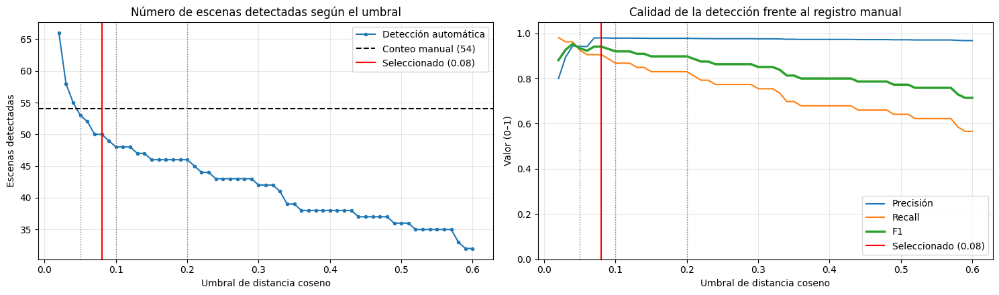

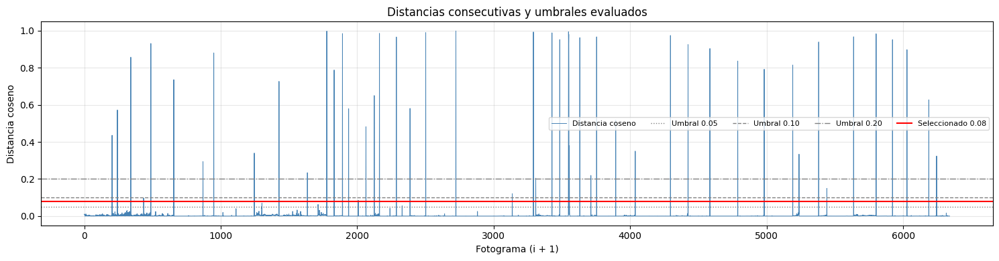

**Umbral seleccionado: 0.08** (elegido por el equipo según la similitud de color entre fotogramas).

- Escenas detectadas: 50 (manual: 54).
- Precisión 0.98, recall 0.91, F1 0.94; 1 falsos cambios y 5 cambios no detectados.
- Umbral estadístico de referencia (media + 3σ): 0.214.
- Solo como referencia de sensibilidad: el máximo F1 del barrido es 0.95, con umbral 0.04.

In [122]:
UMBRAL_ELEGIDO = 0.08

barrido = np.round(np.arange(0.02, 0.601, 0.01), 2)
metricas = [comparar_con_manual(detectar_cambios(distancias, u)) for u in barrido]
n_escenas = np.array([m["vp"] + m["fp"] + 1 for m in metricas])
f1s = np.array([m["f1"] for m in metricas])

# Empates: primero menor diferencia de conteo; luego el umbral central de la meseta,
# que deja el mayor margen ante pequeñas variaciones de las distancias.
f1_max = f1s.round(4).max()
empatados = [k for k in range(len(barrido)) if f1s[k].round(4) == f1_max]
dif_min = min(abs(n_escenas[k] - escenas_manual) for k in empatados)
empatados = [k for k in empatados if abs(n_escenas[k] - escenas_manual) == dif_min]
mejor = empatados[len(empatados) // 2]
UMBRAL_SELECCIONADO = float(UMBRAL_ELEGIDO) if UMBRAL_ELEGIDO is not None else float(barrido[mejor])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
ax1.plot(barrido, n_escenas, marker=".", label="Detección automática")
ax1.axhline(escenas_manual, color="black", ls="--", label=f"Conteo manual ({escenas_manual})")
ax1.set_title("Número de escenas detectadas según el umbral")
ax1.set_xlabel("Umbral de distancia coseno"); ax1.set_ylabel("Escenas detectadas")
ax1.yaxis.get_major_locator().set_params(integer=True)
ax2.plot(barrido, [m["precision"] for m in metricas], label="Precisión")
ax2.plot(barrido, [m["recall"] for m in metricas], label="Recall")
ax2.plot(barrido, f1s, lw=2.5, label="F1")
ax2.set_title("Calidad de la detección frente al registro manual")
ax2.set_xlabel("Umbral de distancia coseno"); ax2.set_ylabel("Valor (0–1)"); ax2.set_ylim(0, 1.05)
for ax in (ax1, ax2):
    for u in UMBRALES[:3]:
        ax.axvline(u, color="gray", ls=":", lw=1)
    ax.axvline(UMBRAL_SELECCIONADO, color="red", lw=1.5, label=f"Seleccionado ({UMBRAL_SELECCIONADO:.2f})")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(np.arange(1, contador), distancias, lw=0.7, color="steelblue", label="Distancia coseno")
for u, estilo in zip(UMBRALES[:3], [":", "--", "-."]):
    ax.axhline(u, color="gray", ls=estilo, lw=1, label=f"Umbral {u:.2f}")
ax.axhline(UMBRAL_SELECCIONADO, color="red", lw=1.5, label=f"Seleccionado {UMBRAL_SELECCIONADO:.2f}")
ax.set_title("Distancias consecutivas y umbrales evaluados")
ax.set_xlabel("Fotograma (i + 1)"); ax.set_ylabel("Distancia coseno"); ax.grid(alpha=0.3); ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

r_sel = comparar_con_manual(detectar_cambios(distancias, UMBRAL_SELECCIONADO))
display(Markdown(
    f"**Umbral seleccionado: {UMBRAL_SELECCIONADO:.2f}** "
    f"({'elegido por el equipo según la similitud de color entre fotogramas' if UMBRAL_ELEGIDO is not None else 'máximo F1 del barrido'}).\n\n"
    f"- Escenas detectadas: {r_sel['vp'] + r_sel['fp'] + 1} (manual: {escenas_manual}).\n"
    f"- Precisión {r_sel['precision']:.2f}, recall {r_sel['recall']:.2f}, F1 {r_sel['f1']:.2f}; "
    f"{r_sel['fp']} falsos cambios y {r_sel['fn']} cambios no detectados.\n"
    f"- Umbral estadístico de referencia (media + 3σ): {umbral_estadistico:.3f}.\n"
    f"- Solo como referencia de sensibilidad: el máximo F1 del barrido es {f1s[mejor]:.2f}, con umbral {barrido[mejor]:.2f}."))

#### Justificación del umbral elegido

(Valores obtenidos con el registro manual: 54 escenas, 53 cambios.)

- **Umbral elegido (0,08):** se seleccionó porque los fotogramas del video comparten una gama de colores muy similar. En la mayoría de los planos predominan el verde del césped y los colores de los uniformes, de modo que los histogramas de fotogramas consecutivos se parecen mucho y la transición de color entre un plano y otro no es tan brusca. En estas condiciones, varios cortes reales producen distancias coseno bajas, inferiores a 0,10, y un umbral de 0,08 permite reconocerlos sin confundirlos con la variación normal dentro de una misma toma, que en el 99 % de los casos es menor a 0,04.
- **Resultado con 0,08:** se detectan **50 escenas** frente a 54 manuales: 48 cortes correctos, **1 falso cambio** (el destello blanco de 01:58,3) y **5 cortes no detectados**. Se obtiene precisión 0,98, recall 0,91 y F1 0,94.
- **Comparación con los umbrales probados (0,05; 0,10; 0,20):** con 0,05 se detectan 53 escenas y solo se pierden 4 cortes, pero aparecen 3 falsos cambios (precisión 0,94, F1 0,93): además del destello de 01:58,3, se marcan como cortes dos movimientos dentro de una misma toma, la celebración con cámara en mano (00:43,4; d ≈ 0,07) y la escena del trofeo (00:57,1; d = 0,063). Con 0,10 y 0,20 se mantiene un solo falso cambio, pero se pierden 7 y 9 cortes reales (F1 0,92 y 0,90). El valor de 0,08 queda en un punto intermedio: conserva la precisión de los umbrales altos y recupera dos cortes que con 0,10 no se detectaban (01:06,9 con d = 0,085 y 00:14,5 con d = 0,097). Es decir, 0,08 queda justo entre ambos grupos: por encima de los movimientos dentro de una toma (≈ 0,06–0,07) y por debajo de los cortes suaves entre planos de colores parecidos.
- **Barrido:** el máximo F1 del barrido es 0,95 con 0,04 (2 omisiones, pero 3 falsos cambios); con valores más bajos los falsos cambios aumentan rápidamente (13 con 0,02). Se prefirió 0,08 porque deja un margen mayor frente a las pequeñas variaciones entre fotogramas de una misma toma.
- **Umbral estadístico (media + 3σ = 0,214):** resulta demasiado alto para este video (45 escenas, 10 omisiones). Los cortes muy marcados, con distancias cercanas a 1, elevan la desviación estándar, mientras que muchos cortes reales tienen distancias pequeñas.

### 3.6. Detección automática de escenas

Con el umbral seleccionado se aplican las mismas reglas de 3.5 (umbral + separación mínima). Cada cambio marca el **primer fotograma** de una escena nueva; la escena `k` abarca el intervalo `[inicio_k, inicio_{k+1})`, igual que en la tabla manual, por lo que no hay huecos ni solapamientos. La última columna indica si el cambio coincide (±0,75 s) con un cambio del registro manual.

Umbral utilizado: 0.08
Cambios detectados: 49
Número total de escenas detectadas automáticamente: 50


| Cambio | Fotograma | Tiempo | Distancia | ¿Coincide con el manual? |
|---:|---:|:---:|---:|:---:|
| 1 | 204 | 00:06.8 | 0.436 | Sí |
| 2 | 243 | 00:08.1 | 0.572 | Sí |
| 3 | 341 | 00:11.4 | 0.857 | Sí |
| 4 | 435 | 00:14.5 | 0.097 | Sí |
| 5 | 488 | 00:16.3 | 0.931 | Sí |
| 6 | 656 | 00:21.9 | 0.736 | Sí |
| 7 | 870 | 00:29.0 | 0.293 | Sí |
| 8 | 949 | 00:31.6 | 0.880 | Sí |
| 9 | 1246 | 00:41.5 | 0.340 | Sí |
| 10 | 1427 | 00:47.6 | 0.726 | Sí |
| 11 | 1635 | 00:54.5 | 0.234 | Sí |
| 12 | 1777 | 00:59.2 | 0.997 | Sí |
| 13 | 1831 | 01:01.0 | 0.788 | Sí |
| 14 | 1892 | 01:03.1 | 0.984 | Sí |
| 15 | 1937 | 01:04.6 | 0.579 | Sí |
| 16 | 2008 | 01:06.9 | 0.085 | Sí |
| 17 | 2064 | 01:08.8 | 0.482 | Sí |
| 18 | 2125 | 01:10.8 | 0.650 | Sí |
| 19 | 2163 | 01:12.1 | 0.985 | Sí |
| 20 | 2287 | 01:16.2 | 0.965 | Sí |
| 21 | 2387 | 01:19.6 | 0.581 | Sí |
| 22 | 2502 | 01:23.4 | 0.989 | Sí |
| 23 | 2723 | 01:30.8 | 0.998 | Sí |
| 24 | 3136 | 01:44.5 | 0.120 | Sí |
| 25 | 3291 | 01:49.7 | 0.993 | Sí |
| 26 | 3308 | 01:50.3 | 0.205 | Sí |
| 27 | 3427 | 01:54.2 | 0.988 | Sí |
| 28 | 3484 | 01:56.1 | 0.952 | Sí |
| 29 | 3548 | 01:58.3 | 0.993 | No (falso cambio) |
| 30 | 3631 | 02:01.0 | 0.962 | Sí |
| 31 | 3712 | 02:03.7 | 0.219 | Sí |
| 32 | 3754 | 02:05.1 | 0.966 | Sí |
| 33 | 3894 | 02:09.8 | 0.517 | Sí |
| 34 | 4037 | 02:14.6 | 0.350 | Sí |
| 35 | 4295 | 02:23.2 | 0.974 | Sí |
| 36 | 4424 | 02:27.5 | 0.924 | Sí |
| 37 | 4584 | 02:32.8 | 0.903 | Sí |
| 38 | 4788 | 02:39.6 | 0.836 | Sí |
| 39 | 4982 | 02:46.1 | 0.792 | Sí |
| 40 | 5191 | 02:53.0 | 0.815 | Sí |
| 41 | 5237 | 02:54.6 | 0.334 | Sí |
| 42 | 5381 | 02:59.4 | 0.939 | Sí |
| 43 | 5441 | 03:01.4 | 0.150 | Sí |
| 44 | 5637 | 03:07.9 | 0.967 | Sí |
| 45 | 5802 | 03:13.4 | 0.983 | Sí |
| 46 | 5922 | 03:17.4 | 0.951 | Sí |
| 47 | 6028 | 03:20.9 | 0.897 | Sí |
| 48 | 6188 | 03:26.3 | 0.627 | Sí |
| 49 | 6245 | 03:28.2 | 0.324 | Sí |

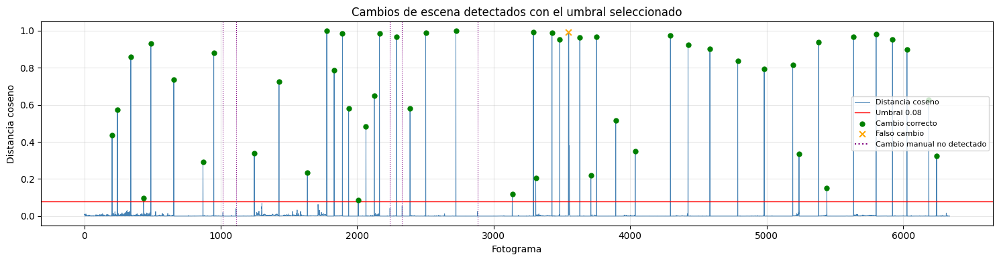

Tabla exportada: escenas_automaticas.csv


In [123]:
cambios_auto = detectar_cambios(distancias, UMBRAL_SELECCIONADO)
evaluacion = comparar_con_manual(cambios_auto)
falsos = set(evaluacion["falsos"])

inicios_auto = [0] + cambios_auto.tolist()
finales_auto = cambios_auto.tolist() + [contador]
escenas_auto = [{"escena": k + 1, "inicio_frame": a, "fin_frame": b,
                 "tiempo_inicial": tiempo_texto(a / fps), "tiempo_final": tiempo_texto(b / fps)}
                for k, (a, b) in enumerate(zip(inicios_auto, finales_auto))]
assert sum(e["fin_frame"] - e["inicio_frame"] for e in escenas_auto) == contador

print(f"Umbral utilizado: {UMBRAL_SELECCIONADO:.2f}")
print(f"Cambios detectados: {len(cambios_auto)}")
print(f"Número total de escenas detectadas automáticamente: {len(escenas_auto)}")

lineas = ["| Cambio | Fotograma | Tiempo | Distancia | ¿Coincide con el manual? |", "|---:|---:|:---:|---:|:---:|"]
for n, f in enumerate(cambios_auto, start=1):
    lineas.append(f"| {n} | {f} | {tiempo_texto(f / fps)} | {distancias[f - 1]:.3f} | {'No (falso cambio)' if f in falsos else 'Sí'} |")
display(Markdown("\n".join(lineas)))

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(np.arange(1, contador), distancias, lw=0.7, color="steelblue", label="Distancia coseno")
ax.axhline(UMBRAL_SELECCIONADO, color="red", lw=1, label=f"Umbral {UMBRAL_SELECCIONADO:.2f}")
ok = [f for f in cambios_auto if f not in falsos]
ax.scatter(ok, distancias[np.array(ok, dtype=int) - 1], color="green", zorder=3, s=25, label="Cambio correcto")
if falsos:
    fl = sorted(falsos)
    ax.scatter(fl, distancias[np.array(fl) - 1], color="orange", marker="x", zorder=3, s=40, label="Falso cambio")
for f in cambios_manual[evaluacion["omitidos"]]:
    ax.axvline(f, color="purple", ls=":", lw=0.8)
ax.plot([], [], color="purple", ls=":", label="Cambio manual no detectado")
ax.set_title("Cambios de escena detectados con el umbral seleccionado")
ax.set_xlabel("Fotograma"); ax.set_ylabel("Distancia coseno"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

with (RAIZ / "escenas_automaticas.csv").open("w", encoding="utf-8-sig", newline="") as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=list(escenas_auto[0]))
    escritor.writeheader()
    escritor.writerows(escenas_auto)
print("Tabla exportada: escenas_automaticas.csv")

### 3.7. Obtención de fotogramas representativos

Elegir simplemente el primer fotograma de cada escena es arriesgado: suele estar en plena transición (desenfoque, fundido, restos del plano anterior). Elegir el fotograma central es mejor, pero no garantiza que sea *típico* de la escena.

Se usa el **fotograma más cercano al centroide** de la escena en el espacio de características: se calcula el vector promedio (centroide) de todos sus fotogramas y se elige el fotograma cuya distancia coseno a ese promedio es mínima. Es el fotograma que mejor resume la apariencia global de la escena. *No es un medoide en sentido estricto*: el medoide minimiza la suma de distancias a todos los elementos del conjunto, lo que requiere comparar todos los pares de fotogramas; comparar solo contra el centroide da un resultado muy parecido con mucho menos cálculo. Se descartan los 3 fotogramas de cada borde (0,1 s) cuando la escena es suficientemente larga, para evitar transiciones. El tiempo mostrado es `fotograma / fps`.

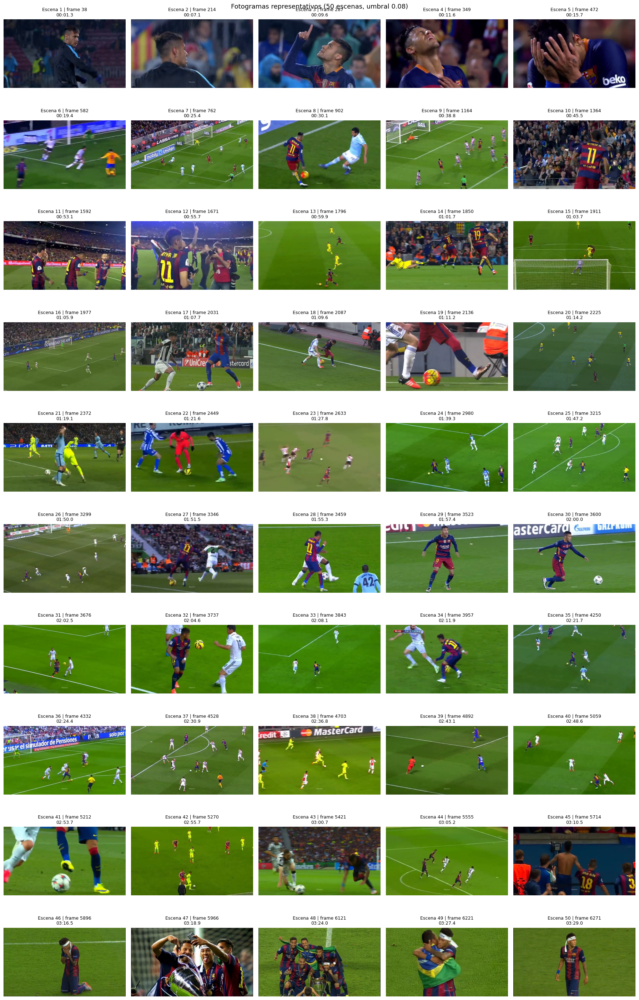

Imágenes guardadas en: fotogramas_representativos/


In [124]:
MARGEN_BORDE = 3
CARPETA_REPRESENTATIVOS = RAIZ / "fotogramas_representativos"
CARPETA_REPRESENTATIVOS.mkdir(exist_ok=True)
for ruta in CARPETA_REPRESENTATIVOS.glob("escena_*.jpg"):
    ruta.unlink()          # evita mezclar resultados de un umbral anterior

def mas_cercano_al_centroide(a, b):
    if b - a > 2 * MARGEN_BORDE + 1:
        a, b = a + MARGEN_BORDE, b - MARGEN_BORDE
    bloque = caracteristicas[a:b]
    centro = bloque.mean(axis=0)
    sim = bloque @ centro / (np.linalg.norm(bloque, axis=1) * np.linalg.norm(centro) + 1e-12)
    return a + int(np.argmax(sim))

representativos = []
for e in escenas_auto:
    f = mas_cercano_al_centroide(e["inicio_frame"], e["fin_frame"])
    imagen = cv2.imread(str(CARPETA_FRAMES / f"frame_{f:05d}.jpg"))
    if imagen is None:
        raise RuntimeError(f"No se pudo leer el fotograma representativo {f}.")
    ruta = CARPETA_REPRESENTATIVOS / f"escena_{e['escena']:03d}_frame_{f:05d}.jpg"
    cv2.imwrite(str(ruta), imagen, [cv2.IMWRITE_JPEG_QUALITY, 95])
    e["frame_representativo"] = f
    representativos.append({"escena": e["escena"], "fotograma": f, "tiempo": tiempo_texto(f / fps),
                            "imagen": cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)})

COLUMNAS_REP = 5
filas_rep = math.ceil(len(representativos) / COLUMNAS_REP)
fig, ejes = plt.subplots(filas_rep, COLUMNAS_REP, figsize=(18, 2.9 * filas_rep), squeeze=False)
for eje in ejes.flat:
    eje.axis("off")
for eje, r in zip(ejes.flat, representativos):
    eje.imshow(r["imagen"])
    eje.set_title(f"Escena {r['escena']} | frame {r['fotograma']}\n{r['tiempo']}", fontsize=9)
fig.suptitle(f"Fotogramas representativos ({len(representativos)} escenas, umbral {UMBRAL_SELECCIONADO:.2f})", fontsize=13)
plt.tight_layout(); plt.show()
print(f"Imágenes guardadas en: {CARPETA_REPRESENTATIVOS.name}/")

#### Interpretación de los fotogramas representativos

Con el umbral 0,08 se obtuvieron **50 escenas** (54 en el registro manual), y los fotogramas representativos **sí permiten reconocer las partes principales del video**, en el mismo orden en que aparecen:

- **Inicio (escenas 1–5):** primeros planos de Neymar en el calentamiento, mirando al cielo y llevándose las manos a la cabeza. Aunque todos son planos del mismo jugador, el algoritmo los separa porque cambian el fondo, la iluminación y el encuadre.
- **Parte central (≈ 00:16–02:55):** regates y jugadas contra rivales con uniformes distintos (blanco, celeste, amarillo, franjas, rojo). Es la parte más difícil de segmentar: casi todos los fotogramas comparten el **césped verde**, así que varios representativos consecutivos se parecen a simple vista aunque correspondan a jugadas diferentes.
- **Final (≈ 03:07–03:31):** celebraciones, Neymar arrodillado, la copa de Champions League y el abrazo con la bandera de Brasil. Son escenas con colores muy distintos al campo de juego (tribuna, trofeo, bandera), por eso el algoritmo las detecta con distancias altas.

**Efecto de los errores en el resumen.** El único falso cambio (el destello de 01:58,3) agrega un representativo casi repetido del mismo plano. Las 5 escenas no detectadas quedan fusionadas con la escena anterior, así que su plano no tiene un representativo propio; por eso hay menos representativos que escenas manuales, sobre todo en la parte de jugadas sobre césped. El análisis detallado de cada error y sus causas está en la sección 4.4.

**Conclusión de esta etapa:** el resumen visual es fiel al contenido general del video, y la selección del fotograma más cercano al centroide evita fotogramas borrosos o de transición. La principal limitación es que un histograma de color no capta la forma ni la posición de los objetos. Un descriptor espacial (histogramas por regiones) o las características de una red preentrenada podría separar mejor los planos de fútbol.

### 3.8. Generación de GIF resumen

Los fotogramas representativos se reducen a 480 × 270 píxeles (misma relación 16:9) para que el archivo sea liviano, y a cada uno se le añade una franja con el número de escena, el fotograma y el tiempo. Cada imagen se muestra 0,8 s, suficiente para reconocerla sin que el resumen se alargue demasiado; el GIF se repite indefinidamente (`loop=0`).

Pillow convierte cada imagen a una paleta de 256 colores, limitación propia del formato GIF; por eso puede notarse un leve bandeado en degradados. En Colab, descargar `escenas.gif` desde el panel de archivos antes de cerrar la sesión.

escenas.gif: 50 cuadros, 40.0 s, 3.40 MiB


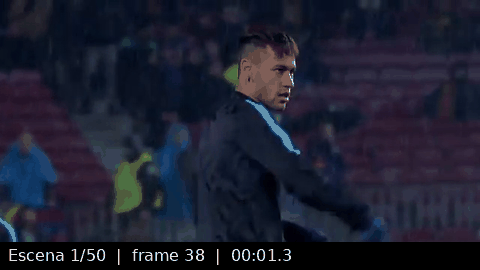

In [125]:
from PIL import ImageFont
from matplotlib import font_manager

RUTA_GIF = RAIZ / "escenas.gif"
TAMANO_GIF = (480, 270)
DURACION_MS = 800
fuente = ImageFont.truetype(font_manager.findfont("DejaVu Sans"), 16)

cuadros = []
for r in representativos:
    cuadro = PILImage.fromarray(r["imagen"]).resize(TAMANO_GIF, PILImage.LANCZOS)
    dibujo = ImageDraw.Draw(cuadro)
    dibujo.rectangle([0, TAMANO_GIF[1] - 28, TAMANO_GIF[0], TAMANO_GIF[1]], fill="black")
    dibujo.text((8, TAMANO_GIF[1] - 24),
                f"Escena {r['escena']}/{len(representativos)}  |  frame {r['fotograma']}  |  {r['tiempo']}",
                fill="white", font=fuente)
    cuadros.append(cuadro)

cuadros[0].save(RUTA_GIF, save_all=True, append_images=cuadros[1:], duration=DURACION_MS, loop=0, optimize=True)

with PILImage.open(RUTA_GIF) as gif:
    if gif.n_frames != len(representativos):
        raise RuntimeError("El GIF no contiene un cuadro por escena.")
print(f"{RUTA_GIF.name}: {len(cuadros)} cuadros, {len(cuadros) * DURACION_MS / 1000:.1f} s, "
      f"{RUTA_GIF.stat().st_size / 1024**2:.2f} MiB")
display(Image(filename=str(RUTA_GIF)))

## 4. Comparación entre detección manual y automática

En esta sección se compara el **registro manual** (punto 2) con la **detección automática** (punto 3.6, con el umbral seleccionado en 3.5).

Se usan las mismas reglas definidas en 3.5:
- Un cambio automático es **correcto** si hay un cambio manual a ±0,75 s.
- Un cambio automático sin pareja manual es un **falso cambio** (el algoritmo "corta" donde no hay escena nueva).
- Un cambio manual sin pareja automática es un **cambio no detectado**.

### 4.1. Tabla comparativa

In [126]:
n_manual = len(escenas)
n_auto = len(escenas_auto)

tabla = f"""| Método | Número de escenas |
|---|---:|
| Conteo manual | {n_manual} |
| Detección automática (umbral {UMBRAL_SELECCIONADO:.2f}) | {n_auto} |
| Diferencia | {abs(n_manual - n_auto)} |
"""
display(Markdown(tabla))

detalle = f"""| Resultado de la comparación | Cantidad |
|---|---:|
| Cambios correctamente detectados | {evaluacion['vp']} |
| Falsos cambios (detectados, pero no son escena nueva) | {evaluacion['fp']} |
| Cambios reales no detectados | {evaluacion['fn']} |
| Precisión = correctos / detectados | {evaluacion['precision']:.2f} |
| Recall = correctos / cambios manuales | {evaluacion['recall']:.2f} |
"""
display(Markdown(detalle))

| Método | Número de escenas |
|---|---:|
| Conteo manual | 54 |
| Detección automática (umbral 0.08) | 50 |
| Diferencia | 4 |


| Resultado de la comparación | Cantidad |
|---|---:|
| Cambios correctamente detectados | 48 |
| Falsos cambios (detectados, pero no son escena nueva) | 1 |
| Cambios reales no detectados | 5 |
| Precisión = correctos / detectados | 0.98 |
| Recall = correctos / cambios manuales | 0.91 |


### 4.2. Ejemplos de cada caso

Para cada tipo de resultado se listan ejemplos con su tiempo y su distancia coseno, y luego se muestran los dos fotogramas a cada lado del cambio (**antes** y **después**) para poder ver qué ocurrió.

- **Correctos:** cambio automático y la escena manual con la que coincide.
- **Falsos cambios:** cambio automático sin escena manual cercana.
- **No detectados:** escena manual cuyo inicio no fue encontrado. Como el pico de distancia puede caer unos fotogramas antes o después del corte, se busca el pico de distancia más alto en ±0,75 s alrededor y se muestra ese punto: su distancia quedó **por debajo del umbral**.

In [127]:
correctos = [f for f in cambios_auto if f not in falsos]
falsos_lista = sorted(falsos)
omitidos = evaluacion["omitidos"]

print(f"ESCENAS CORRECTAMENTE DETECTADAS ({len(correctos)}). Ejemplos:")
for f in correctos[:5]:
    im = np.argmin(np.abs(cambios_manual - f))   # cambio manual más cercano
    e = escenas[im + 1]
    print(f"  {tiempo_texto(f / fps)} (frame {f}, d={distancias[f - 1]:.3f})  ->  manual {e['tiempo_inicial']}: {e['descripcion']}")

print(f"\nFALSOS CAMBIOS ({len(falsos_lista)}):")
for f in falsos_lista:
    print(f"  {tiempo_texto(f / fps)} (frame {f}, d={distancias[f - 1]:.3f})")

def pico_cercano(frame_manual):
    """Fotograma (i + 1) con la mayor distancia en ±TOLERANCIA alrededor de un cambio manual."""
    inicio = max(0, frame_manual - 1 - TOLERANCIA)
    ventana = distancias[inicio: frame_manual + TOLERANCIA]
    return inicio + int(np.argmax(ventana)) + 1

print(f"\nCAMBIOS REALES NO DETECTADOS ({len(omitidos)}):")
for im in omitidos:
    e = escenas[im + 1]
    f = pico_cercano(cambios_manual[im])
    print(f"  Escena {e['escena']} ({e['tiempo_inicial']}): {e['descripcion']}  "
          f"-> pico más alto cercano d={distancias[f - 1]:.3f} (umbral {UMBRAL_SELECCIONADO:.2f})")

ESCENAS CORRECTAMENTE DETECTADAS (48). Ejemplos:
  00:06.8 (frame 204, d=0.436)  ->  manual 00:06.8: Neymar de espaldas, con las luces del estadio al fondo.
  00:08.1 (frame 243, d=0.572)  ->  manual 00:08.1: Neymar con camiseta del Barcelona entre el público, señalando hacia arriba.
  00:11.4 (frame 341, d=0.857)  ->  manual 00:11.4: Primer plano: Neymar mira al cielo y baja la cabeza (una sola toma).
  00:14.5 (frame 435, d=0.097)  ->  manual 00:14.5: Plano más cerrado: Neymar se lleva las manos a la cabeza.
  00:16.3 (frame 488, d=0.931)  ->  manual 00:16.3: Conducción por la banda con camiseta naranja; la cámara se aleja y gira hasta el área.

FALSOS CAMBIOS (1):
  01:58.3 (frame 3548, d=0.993)

CAMBIOS REALES NO DETECTADOS (5):
  Escena 10 (00:33.9): Plano general del ataque.  -> pico más alto cercano d=0.020 (umbral 0.08)
  Escena 11 (00:37.1): Plano general desde otro ángulo, con la portería.  -> pico más alto cercano d=0.040 (umbral 0.08)
  Escena 23 (01:14.7): Plano más cercan

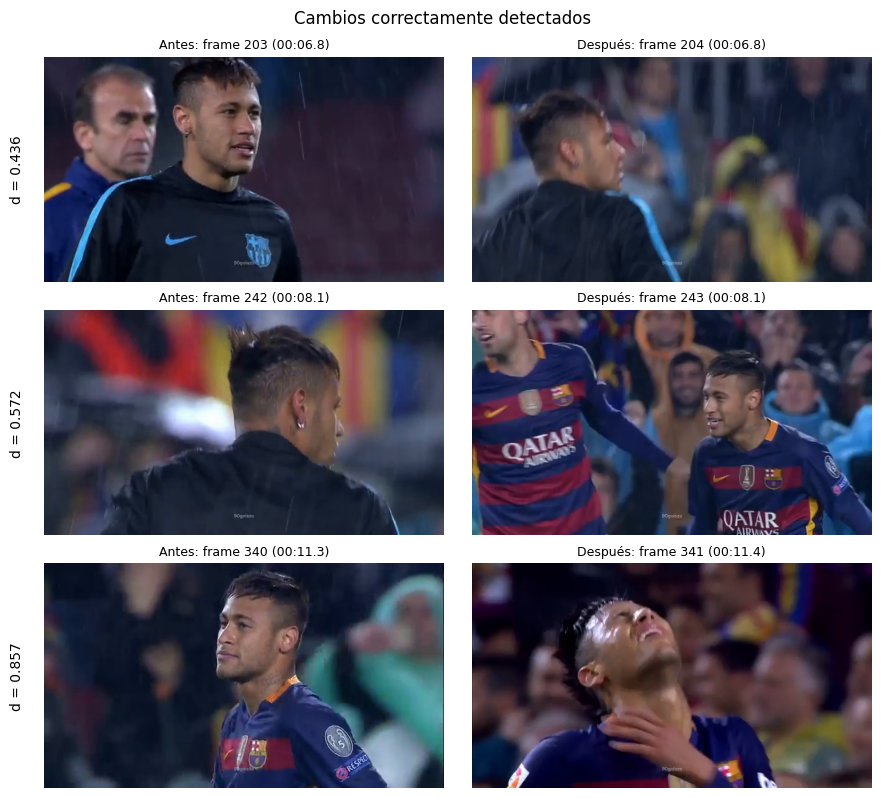

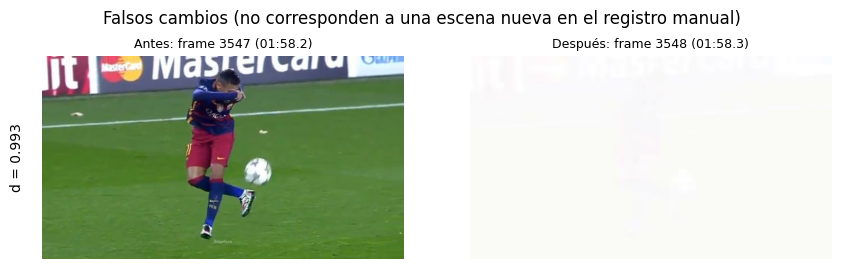

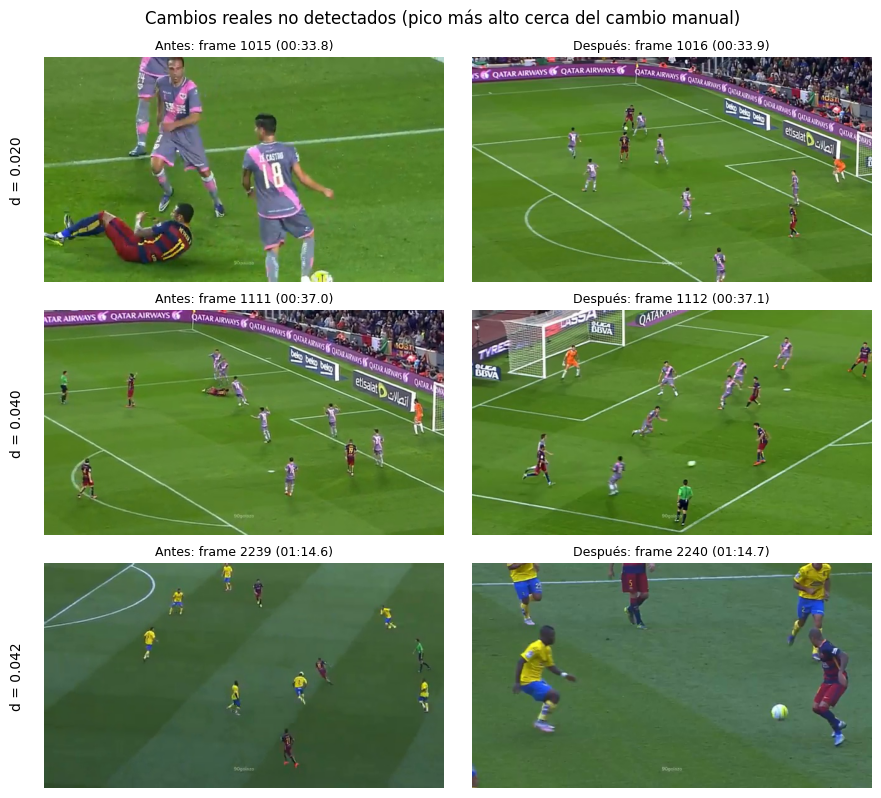

In [128]:
def mostrar_cortes(frames_cambio, titulo):
    """Muestra el fotograma anterior y el posterior de cada cambio (una fila por cambio)."""
    if len(frames_cambio) == 0:
        print(f"{titulo}: no hay ejemplos.")
        return
    fig, ejes = plt.subplots(len(frames_cambio), 2, figsize=(9, 2.7 * len(frames_cambio)), squeeze=False)
    for fila, f in enumerate(frames_cambio):
        for col, indice in enumerate([f - 1, f]):
            imagen = cv2.imread(str(CARPETA_FRAMES / f"frame_{indice:05d}.jpg"))
            ejes[fila, col].imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
            ejes[fila, col].set_title(f"{'Antes' if col == 0 else 'Después'}: frame {indice} ({tiempo_texto(indice / fps)})", fontsize=9)
            ejes[fila, col].axis("off")
        ejes[fila, 0].text(-0.05, 0.5, f"d = {distancias[f - 1]:.3f}", transform=ejes[fila, 0].transAxes,
                           rotation=90, va="center", ha="right", fontsize=10)
    fig.suptitle(titulo, fontsize=12)
    plt.tight_layout()
    plt.show()

mostrar_cortes(correctos[:3], "Cambios correctamente detectados")
mostrar_cortes(falsos_lista[:3], "Falsos cambios (no corresponden a una escena nueva en el registro manual)")
mostrar_cortes([pico_cercano(cambios_manual[im]) for im in omitidos[:3]],
               "Cambios reales no detectados (pico más alto cerca del cambio manual)")

### 4.3. Distancias de cada tipo de resultado

Un diagrama de caja resume las distancias coseno de los cambios correctos, de los falsos cambios y del pico más alto cerca de cada cambio no detectado. Permite ver si los errores están cerca del umbral (se podrían corregir moviéndolo) o lejos (son un límite del método).

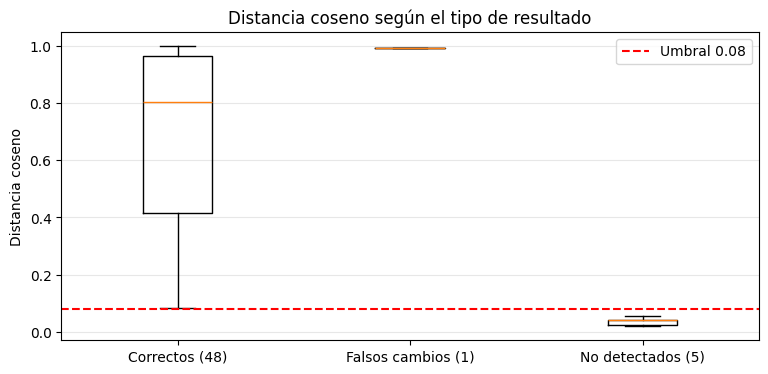

Mediana de distancia - correctos: 0.803
Mediana de distancia - falsos cambios: 0.993
Mediana del pico cercano - no detectados: 0.040


In [129]:
# Comparación de las distancias de cada grupo: ¿qué tan lejos quedaron del umbral?
d_correctos = [distancias[f - 1] for f in correctos]
d_falsos = [distancias[f - 1] for f in falsos_lista]
d_omitidos = [distancias[pico_cercano(cambios_manual[im]) - 1] for im in omitidos]

plt.figure(figsize=(9, 4))
plt.boxplot([d_correctos, d_falsos, d_omitidos], showfliers=True)
plt.xticks([1, 2, 3], [f"Correctos ({len(d_correctos)})", f"Falsos cambios ({len(d_falsos)})", f"No detectados ({len(d_omitidos)})"])
plt.axhline(UMBRAL_SELECCIONADO, color="red", ls="--", label=f"Umbral {UMBRAL_SELECCIONADO:.2f}")
plt.title("Distancia coseno según el tipo de resultado")
plt.ylabel("Distancia coseno")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.show()

print(f"Mediana de distancia - correctos: {np.median(d_correctos):.3f}")
if d_falsos:
    print(f"Mediana de distancia - falsos cambios: {np.median(d_falsos):.3f}")
if d_omitidos:
    print(f"Mediana del pico cercano - no detectados: {np.median(d_omitidos):.3f}")

### 4.4. Análisis de los resultados y posibles causas

**Resumen.** El registro manual tiene **54 escenas** y la detección automática con umbral 0,08 encontró **50** (diferencia de 4). De los 49 cambios automáticos, **48 son correctos** y **1 es un falso cambio**, y hay **5 cambios reales que no se detectaron** (49 − 1 + 5 = 53 cambios manuales). En este caso la diferencia en el conteo coincide casi por completo con las omisiones, pero no siempre es así: con otros umbrales (por ejemplo 0,04) el conteo se acerca mucho al manual mientras falsos cambios y omisiones se compensan. Por eso hay que revisar *dónde* está cada corte y no solo cuántos hay.

**Escenas correctamente detectadas (48).** Son la gran mayoría. Los ejemplos más claros son los cortes entre planos con **colores muy distintos**: de un primer plano de Neymar (fondo oscuro, piel, camiseta azul) a un plano general del campo (casi todo verde), como en 00:16,3 (d = 0,931) o 00:21,9 (d = 0,736), o del partido a Neymar arrodillado en la celebración final, en 03:13,4 (d = 0,983). Ahí el histograma de color cambia casi por completo y la distancia coseno se acerca a 1. La mediana de las distancias de los cambios correctos es ≈ 0,80, muy por encima del umbral.

**Falso cambio (1).** **01:58,3 (d = 0,993):** un **destello blanco** de un solo fotograma junto a la publicidad de MasterCard. El fotograma anterior y el posterior son prácticamente iguales, así que no es un corte. Como el blanco concentra casi todos los píxeles en pocos bins, la distancia es casi 1. Es un error real del método: comparar solo fotogramas consecutivos no distingue un destello aislado de un corte.

**Cambios reales no detectados (5).** Todos tienen un pico de distancia por debajo de 0,08 (entre 0,020 y 0,055; mediana ≈ 0,04) y corresponden al mismo tipo de caso:
- **Cortes entre planos de fútbol sobre césped** (00:33,9; 00:37,1; 01:14,7; 01:17,6; 01:36,0): planos generales, planos cercanos y repeticiones de la misma jugada. Los dos planos están dominados por el **verde del césped** y por los mismos colores de uniformes, así que sus histogramas son casi iguales aunque el encuadre sea distinto (por ejemplo, d = 0,020 en 00:33,9 y 0,025 en 01:36,0).
- Con 0,08 sí se detectan dos cortes que se perdían con 0,10: el paso entre los primeros planos de Neymar en 00:14,5 (d = 0,097) y el corte de 01:06,9 (d = 0,085). Esto confirma que, en un video con colores tan parecidos entre planos, un umbral bajo recupera cambios de escena suaves.

El histograma no guarda información de *dónde* están los colores ni de la forma de los objetos, y eso explica las cinco omisiones.

**Conclusión del análisis.** El diagrama de caja de 4.3 muestra que los no detectados quedan **por debajo** del umbral (≈ 0,02–0,055), mientras que el único falso cambio queda muy por encima (≈ 0,99). Bajar más el umbral recupera parte de las omisiones, pero aparecen falsos cambios por movimientos de cámara dentro de la misma toma: con 0,05 se pierden 4 cortes y aparecen 3 falsos cambios (00:43,4 y 00:57,1, además del destello), y con 0,02 ya hay 13. Los errores restantes no dependen tanto del umbral como de lo que el vector de características puede representar.

## 5. Conclusiones

1. **La detección automática fue cercana al análisis manual y muy precisa, pero el conteo de escenas por sí solo no basta.** Se detectaron 50 escenas frente a 54 manuales; el 98 % de los cortes detectados coincide con un corte manual (precisión 0,98) y se encontró el 91 % de los cortes reales (recall 0,91). Con otros umbrales el conteo puede acercarse mucho al manual mientras falsos cambios y omisiones se compensan, así que evaluamos con correspondencia de tiempos (precisión, recall y F1) y no solo con la cantidad de escenas.

2. **El umbral tiene una influencia muy fuerte.** Con 0,05; 0,10 y 0,20 se detectaron 53, 48 y 46 escenas. Al subir el umbral se pierden cortes reales (4, 7 y 9 omisiones) y, al bajarlo demasiado, aparecen falsos cambios (3 con 0,05). El histograma de distancias explica este comportamiento: el 99 % de los pares consecutivos tiene una distancia menor a 0,04 (la mediana es ≈ 0,0001) y varios cortes reales quedan poco por encima de ese nivel, porque los planos comparten la misma gama de colores. Por eso elegimos **0,08**: es lo bastante bajo para captar los cambios de color suaves entre planos sobre el césped y lo bastante alto para no confundirlos con variaciones dentro de una misma toma. El umbral estadístico (media + 3σ = 0,214) resultó demasiado alto, porque los cortes muy marcados (d ≈ 1) aumentan la desviación estándar.

3. **Los errores se explican por el tipo de característica utilizada: un histograma de color solo "ve" colores.** Falla cuando dos planos distintos tienen los mismos colores (cortes entre planos de fútbol sobre el césped verde o primeros planos seguidos de Neymar) y genera picos en efectos de edición (el destello blanco de 01:58,3); con umbrales más bajos, también cuando la cámara se mueve o cambia la iluminación dentro de una misma toma (por ejemplo, 00:43,4 y 00:57,1 con 0,05).

4. **La referencia manual también tuvo errores.** Su primera versión, hecha con láminas cada 0,5 s, tenía cuatro límites mal puestos que se descubrieron al revisar los errores del método y se corrigieron después con un recuento viendo el video completo. Por eso las métricas deben leerse como optimistas.

5. **Mejoras posibles al procedimiento.**
   - Calcular histogramas **por regiones** de la imagen (por ejemplo, una cuadrícula de 3 × 3) para captar *dónde* están los colores y así diferenciar un plano general de un plano cercano sobre el césped.
   - Reducir el peso del brillo (V) o normalizar la iluminación, para que un cambio de exposición dentro de la misma toma no se confunda con un corte.
   - Usar características de una **red neuronal preentrenada** (por ejemplo, ResNet), que describen formas y objetos además del color.
   - Ignorar picos aislados de uno o dos fotogramas, como los destellos, comparando el fotograma con varios anteriores y posteriores.
   - Calibrar el umbral con otros videos etiquetados, para que el F1 no dependa del mismo video con el que se evalúa.